# Sentinel-1 Chennai LULC — Clean Working Notebook

**Course:** Deep Learning  
**Student:** Madhumitha Ramakrishnan  
**Student ID:** 100004761  
**University:** SRH University Heidelberg

> This is a cleaned working copy of the uploaded notebook. The original ZIP and Google Drive checkpoint are not modified.

## Important scope and scientific-integrity notes
- This notebook's existing core study area is Chennai. The additional S1_AI4LCC granules audited in the current session are all in France, not eight different countries.
- Do not describe French granules as eight-country data or as independent countries.
- Keep the original Chennai validation set separate. Any new geographical test region must remain excluded from training and model selection.
- Sentinel-1 VV/VH are the model inputs. Confirm band order, units, calibration, normalization and label mapping from the source data before training.
- Report only metrics produced by actually executing the evaluation cells.
- The uploaded notebook has multiple experimental versions. This cleaned copy retains the main workflow and selected diagnostics; it does not certify that every retained cell is ready to run in sequence.


## 1. Environment and Sentinel-1 monthly data
Run the environment setup first. Then authenticate Earth Engine if required, define the study area, and create monthly Sentinel-1 composites. Review the dates, orbit filtering, polarization and missing-month handling before export.

In [ ]:
# Cell 1: Check the project environment

import sys
import platform
import importlib.util

print("=" * 55)
print("SENTINEL-1 LULC PROJECT — ENVIRONMENT CHECK")
print("=" * 55)

print("Python version:", sys.version)
print("Platform:", platform.platform())

# Check PyTorch
if importlib.util.find_spec("torch") is not None:
    import torch

    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("CUDA version:", torch.version.cuda)
    else:
        print("GPU not detected. Check Colab runtime settings.")
else:
    print("\nPyTorch is not installed.")

# Check core geospatial libraries
libraries = [
    "numpy",
    "pandas",
    "matplotlib",
    "rasterio",
    "geopandas",
    "sklearn",
    "huggingface_hub",
]

print("\nLibrary availability:")
for library in libraries:
    installed = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Available' if installed else 'Not installed'}")

print("\nEnvironment check complete.")

SENTINEL-1 LULC PROJECT — ENVIRONMENT CHECK
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0

Library availability:
numpy: Available
pandas: Available
matplotlib: Available
rasterio: Available
geopandas: Available
sklearn: Available
huggingface_hub: Available

Environment check complete.


In [ ]:

# STEP 2: GOOGLE DRIVE AND MODEL BACKUP CHECK

from google.colab import drive
import os

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Sentinel1_LULC_Project"

print("=" * 55)
print("EXISTING PROJECT BACKUP CHECK")
print("=" * 55)

if not os.path.exists(PROJECT_DIR):
    raise FileNotFoundError("Original project folder not found.")

for folder, subfolders, files in os.walk(PROJECT_DIR):
    level = folder.replace(PROJECT_DIR, "").count(os.sep)

    if level > 3:
        subfolders[:] = []
        continue

    print("\nFolder:", os.path.relpath(folder, PROJECT_DIR))

    for filename in files:
        path = os.path.join(folder, filename)
        size = os.path.getsize(path) / (1024 * 1024)

        print(f"  {filename} ({size:.2f} MB)")

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "best_sentinel1_unet_v2.pth"
)

print("\nMODEL CHECK")

if os.path.isfile(MODEL_PATH):
    print("SUCCESS: Original model checkpoint recovered.")
    print("Path:", MODEL_PATH)
    print("Size:", round(os.path.getsize(MODEL_PATH)/1024/1024, 2), "MB")
else:
    print("WARNING: Model checkpoint not found.")

print("\nStep 2 completed.")


Mounted at /content/drive
EXISTING PROJECT BACKUP CHECK

Folder: .
  drive_test.txt (0.00 MB)
  best_sentinel1_unet_v2.pth (7.39 MB)

Folder: data

Folder: models

Folder: results
  Chennai_ESA_WorldCover_2021.tif (0.18 MB)
  Chennai_ESA_WorldCover_2021_Aligned.tif (0.26 MB)
  ESA_Validation_Class_Metrics.csv (0.00 MB)
  ESA_Validation_Confusion_Matrix.csv (0.00 MB)
  Chennai_2021_Monthly_LULC_Maps.png (1.37 MB)

Folder: outputs

Folder: logs

Folder: Monthly_Predictions
  Chennai_LULC_2021_01.tif (0.18 MB)
  Chennai_LULC_2021_02.tif (0.17 MB)
  Chennai_LULC_2021_03.tif (0.18 MB)
  Chennai_LULC_2021_04.tif (0.19 MB)
  Chennai_LULC_2021_05.tif (0.17 MB)
  Chennai_LULC_2021_06.tif (0.16 MB)
  Chennai_LULC_2021_07.tif (0.16 MB)
  Chennai_LULC_2021_08.tif (0.16 MB)
  Chennai_LULC_2021_09.tif (0.17 MB)
  Chennai_LULC_2021_10.tif (0.18 MB)
  Chennai_LULC_2021_11.tif (0.17 MB)
  Chennai_LULC_2021_12.tif (0.17 MB)
  Chennai_2021_Monthly_Class_Distribution.csv (0.00 MB)

MODEL CHECK
SUCCESS: Or

In [ ]:

# STEP 3: INSPECT ORIGINAL MODEL AND RESULTS
# Trusted checkpoint: our own previously saved project file

import torch
import os
import pandas as pd
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/Sentinel1_LULC_Project"

MODEL_PATH = os.path.join(
    PROJECT_DIR, "best_sentinel1_unet_v2.pth"
)

print("=" * 60)
print("ORIGINAL MODEL INSPECTION")
print("=" * 60)

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError("Original checkpoint not found.")

# Only use weights_only=False for a checkpoint you trust.
try:
    checkpoint = torch.load(
        MODEL_PATH,
        map_location="cpu",
        weights_only=False
    )
except Exception as e:
    raise RuntimeError(f"Checkpoint loading failed: {e}")

print("\nCHECKPOINT CONTENTS:")

if isinstance(checkpoint, dict):
    for key, value in checkpoint.items():
        if isinstance(value, torch.Tensor):
            print(key, ":", tuple(value.shape))
        elif isinstance(value, dict):
            print(key, ":", "Dictionary with", len(value), "items")
        else:
            print(key, ":", str(value)[:250])
else:
    print("Checkpoint type:", type(checkpoint))

# Inspect existing evaluation files
print("\nEXISTING EVALUATION RESULTS")

results_dir = os.path.join(PROJECT_DIR, "results")

for filename in [
    "ESA_Validation_Class_Metrics.csv",
    "ESA_Validation_Confusion_Matrix.csv"
]:
    path = os.path.join(results_dir, filename)

    if os.path.isfile(path):
        print("\n", filename)
        try:
            display(pd.read_csv(path))
        except Exception as e:
            print("CSV reading error:", e)
    else:
        print("Missing:", filename)

# Inspect monthly predictions
monthly_dir = os.path.join(
    PROJECT_DIR, "Monthly_Predictions"
)

monthly_files = sorted([
    f for f in os.listdir(monthly_dir)
    if f.lower().endswith(".tif")
]) if os.path.isdir(monthly_dir) else []

print("\nMonthly prediction maps:", len(monthly_files))

for filename in monthly_files:
    print(filename)

print("\nINSPECTION COMPLETED")


ORIGINAL MODEL INSPECTION

CHECKPOINT CONTENTS:
model_state_dict : Dictionary with 92 items
epoch : 13
val_loss : 0.8890116711457571
class_names : Dictionary with 5 items
class_weights : (5,)
normalization_means : [ 68.72029 126.65641]
normalization_stds : [19.140371 35.750645]
input_channels : ['VH', 'VV']
num_classes : 5

EXISTING EVALUATION RESULTS

 ESA_Validation_Class_Metrics.csv


,Class,F1_Score,IoU
0,Urban,0.6984,0.5366
1,Agriculture,0.0099,0.0050
2,Forest/Semi-natural,0.4669,0.3046
3,Wetlands,0.0000,0.0000
4,Water,0.0006,0.0003



 ESA_Validation_Confusion_Matrix.csv


,Class,Urban,Agriculture,Forest/Semi-natural,Wetlands,Water
0,Urban,830482,11572,450378,801,6265
1,Agriculture,47607,2690,81623,27,492
2,Forest/Semi-natural,174489,7433,417317,283,2128
3,Wetlands,5932,1317,14090,0,124
4,Water,20172,385940,222486,0,207



Monthly prediction maps: 12
Chennai_LULC_2021_01.tif
Chennai_LULC_2021_02.tif
Chennai_LULC_2021_03.tif
Chennai_LULC_2021_04.tif
Chennai_LULC_2021_05.tif
Chennai_LULC_2021_06.tif
Chennai_LULC_2021_07.tif
Chennai_LULC_2021_08.tif
Chennai_LULC_2021_09.tif
Chennai_LULC_2021_10.tif
Chennai_LULC_2021_11.tif
Chennai_LULC_2021_12.tif

INSPECTION COMPLETED


In [ ]:
import pandas as pd
import numpy as np
import os

CM_PATH = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/ESA_Validation_Confusion_Matrix.csv"

print("CSV CONTENT:")
print(open(CM_PATH).read())

df = pd.read_csv(CM_PATH)
print("\nDATAFRAME:")
print(df)
print("\nCOLUMNS:")
print(df.columns.tolist())
print("\nSHAPE:", df.shape)

CSV CONTENT:
Class,Urban,Agriculture,Forest/Semi-natural,Wetlands,Water
Urban,830482,11572,450378,801,6265
Agriculture,47607,2690,81623,27,492
Forest/Semi-natural,174489,7433,417317,283,2128
Wetlands,5932,1317,14090,0,124
Water,20172,385940,222486,0,207


DATAFRAME:
                 Class   Urban  Agriculture  Forest/Semi-natural  Wetlands  \
0                Urban  830482        11572               450378       801   
1          Agriculture   47607         2690                81623        27   
2  Forest/Semi-natural  174489         7433               417317       283   
3             Wetlands    5932         1317                14090         0   
4                Water   20172       385940               222486         0   

   Water  
0   6265  
1    492  
2   2128  
3    124  
4    207  

COLUMNS:
['Class', 'Urban', 'Agriculture', 'Forest/Semi-natural', 'Wetlands', 'Water']

SHAPE: (5, 6)


In [ ]:
import ee

PROJECT_ID = "sentinel1-lulc-project"

try:
    ee.Initialize(project=PROJECT_ID)
    print("Google Earth Engine initialized successfully.")

    count = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterDate("2021-01-01", "2022-01-01")
        .size()
        .getInfo()
    )

    print("Sentinel-1 images available for 2021:", count)

except Exception as e:
    print("Earth Engine error:", str(e))

In [ ]:
import numpy as np
import pandas as pd

CM_PATH = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/ESA_Validation_Confusion_Matrix.csv"

# Read the complete 5-class confusion matrix
df = pd.read_csv(CM_PATH)
cm = df.iloc[:, 1:].to_numpy(dtype=np.int64)

class_names = [
    "Urban",
    "Agriculture",
    "Forest/Semi-natural",
    "Wetlands",
    "Water"
]

assert cm.shape == (5, 5), f"Expected 5x5 matrix, got {cm.shape}"

# Calculate metrics
tp = np.diag(cm)
actual = cm.sum(axis=1)
predicted = cm.sum(axis=0)

precision = np.divide(tp, predicted, out=np.zeros(5, dtype=float), where=predicted != 0)
recall = np.divide(tp, actual, out=np.zeros(5, dtype=float), where=actual != 0)

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(5, dtype=float),
    where=(precision + recall) != 0
)

union = actual + predicted - tp
iou = np.divide(tp, union, out=np.zeros(5, dtype=float), where=union != 0)

overall_accuracy = tp.sum() / cm.sum()
macro_f1 = f1.mean()
macro_iou = iou.mean()

# Display results
results = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "IoU": iou,
    "Actual pixels": actual,
    "Predicted pixels": predicted
})

print("BASELINE VALIDATION RESULTS")
print(results.round(4).to_string(index=False))

print("\nOVERALL ACCURACY:", round(overall_accuracy, 4))
print("MACRO F1:", round(macro_f1, 4))
print("MACRO mIoU:", round(macro_iou, 4))
print("TOTAL VALIDATION PIXELS:", int(cm.sum()))

BASELINE VALIDATION RESULTS
              Class  Precision  Recall  F1-score    IoU  Actual pixels  Predicted pixels
              Urban     0.7699  0.6391    0.6984 0.5366        1299498           1078682
        Agriculture     0.0066  0.0203    0.0099 0.0050         132439            408952
Forest/Semi-natural     0.3519  0.6936    0.4669 0.3046         601650           1185894
           Wetlands     0.0000  0.0000    0.0000 0.0000          21463              1111
              Water     0.0225  0.0003    0.0006 0.0003         628805              9216

OVERALL ACCURACY: 0.466
MACRO F1: 0.2352
MACRO mIoU: 0.1693
TOTAL VALIDATION PIXELS: 2683855


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Sentinel1_LULC_Project"

print("SEARCHING FOR TRAINING DATA")
print("=" * 55)

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d not in [" .ipynb_checkpoints"]]

    for file in files:
        if file.endswith((".npy", ".npz", ".tif", ".tiff")):
            path = os.path.join(root, file)
            print(path)

SEARCHING FOR TRAINING DATA
/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021_Aligned.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_01.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_02.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_03.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_04.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_05.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_06.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_07.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_08.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Prediction

In [ ]:
import os

SEARCH_LOCATIONS = [
    "/content",
    "/content/drive/MyDrive"
]

extensions = (".npy", ".npz", ".tif", ".tiff", ".pth", ".pt")

print("SEARCHING FOR ORIGINAL DATA AND MODEL FILES")
print("=" * 60)

found = []

for base in SEARCH_LOCATIONS:
    for root, dirs, files in os.walk(base):
        dirs[:] = [
            d for d in dirs
            if d not in ["node_modules", ".cache", ".ipynb_checkpoints"]
        ]

        for file in files:
            if file.lower().endswith(extensions):
                path = os.path.join(root, file)
                if path not in found:
                    found.append(path)

for path in found:
    print(path)

print("\nTOTAL FILES FOUND:", len(found))

SEARCHING FOR ORIGINAL DATA AND MODEL FILES
/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth
/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021_Aligned.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_01.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_02.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_03.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_04.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_05.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_06.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/Chennai_LULC_2021_07.tif
/content/drive/MyDrive/Sentinel1_LULC_Project/Monthly_Predictions/

In [ ]:
import os
import rasterio

DATA_DIR = "/content/drive/MyDrive/Chennai_LULC_2021"

print("SENTINEL-1 SOURCE DATA AUDIT")
print("=" * 65)

for month in range(1, 13):
    path = os.path.join(DATA_DIR, f"Chennai_S1_2021_{month:02d}.tif")

    if not os.path.exists(path):
        print(f"\nMonth {month:02d}: FILE MISSING")
        continue

    with rasterio.open(path) as src:
        print(f"\nMonth: {month:02d}")
        print("File:", os.path.basename(path))
        print("Dimensions:", src.width, "x", src.height)
        print("Bands:", src.count)
        print("Data types:", src.dtypes)
        print("CRS:", src.crs)
        print("NoData:", src.nodata)
        print("Band descriptions:", src.descriptions)

SENTINEL-1 SOURCE DATA AUDIT

Month: 01
File: Chennai_S1_2021_01.tif
Dimensions: 1633 x 1664
Bands: 2
Data types: ('float64', 'float64')
CRS: EPSG:32644
NoData: None
Band descriptions: ('VH', 'VV')

Month: 02
File: Chennai_S1_2021_02.tif
Dimensions: 1633 x 1664
Bands: 2
Data types: ('float64', 'float64')
CRS: EPSG:32644
NoData: None
Band descriptions: ('VH', 'VV')

Month: 03
File: Chennai_S1_2021_03.tif
Dimensions: 1633 x 1664
Bands: 2
Data types: ('float64', 'float64')
CRS: EPSG:32644
NoData: None
Band descriptions: ('VH', 'VV')

Month: 04
File: Chennai_S1_2021_04.tif
Dimensions: 1633 x 1664
Bands: 2
Data types: ('float64', 'float64')
CRS: EPSG:32644
NoData: None
Band descriptions: ('VH', 'VV')

Month: 05
File: Chennai_S1_2021_05.tif
Dimensions: 1633 x 1664
Bands: 2
Data types: ('float64', 'float64')
CRS: EPSG:32644
NoData: None
Band descriptions: ('VH', 'VV')

Month: 06
File: Chennai_S1_2021_06.tif
Dimensions: 1633 x 1664
Bands: 2
Data types: ('float64', 'float64')
CRS: EPSG:32644
No

In [ ]:
import rasterio
import numpy as np

s1_path = "/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif"

label_paths = [
    "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021.tif",
    "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021_Aligned.tif"
]

with rasterio.open(s1_path) as s1:
    print("SENTINEL-1 REFERENCE")
    print("Shape:", s1.height, s1.width)
    print("CRS:", s1.crs)
    print("Transform:", s1.transform)

    for path in label_paths:
        print("\nLABEL FILE:", path.split("/")[-1])

        with rasterio.open(path) as label:
            print("Shape:", label.height, label.width)
            print("CRS:", label.crs)
            print("Transform:", label.transform)
            print("Same dimensions:", (s1.height, s1.width) == (label.height, label.width))
            print("Same CRS:", s1.crs == label.crs)
            print("Same transform:", s1.transform == label.transform)

            data = label.read(1)
            values, counts = np.unique(data, return_counts=True)

            print("Unique values:", values[:30])
            print("Pixel counts:", counts[:30])

SENTINEL-1 REFERENCE
Shape: 1664 1633
CRS: EPSG:32644
Transform: | 10.00, 0.00, 407780.00|
| 0.00,-10.00, 1442820.00|
| 0.00, 0.00, 1.00|

LABEL FILE: Chennai_ESA_WorldCover_2021.tif
Shape: 1674 1644
CRS: EPSG:32644
Transform: | 10.00, 0.00, 407720.00|
| 0.00,-10.00, 1442870.00|
| 0.00, 0.00, 1.00|
Same dimensions: False
Same CRS: True
Same transform: False
Unique values: [10 20 30 40 50 60 80 90]
Pixel counts: [ 460501    3981  141883  134753 1314406   33761  640995   21776]

LABEL FILE: Chennai_ESA_WorldCover_2021_Aligned.tif
Shape: 1664 1633
CRS: EPSG:32644
Transform: | 10.00, 0.00, 407780.00|
| 0.00,-10.00, 1442820.00|
| 0.00, 0.00, 1.00|
Same dimensions: True
Same CRS: True
Same transform: True
Unique values: [10 20 30 40 50 60 80 90]
Pixel counts: [ 456819    3949  140882  132439 1299498   33457  628805   21463]


In [ ]:
import os

SEARCH_DIRS = [
    "/content/drive/MyDrive/Sentinel1_LULC_Project",
    "/content/drive/MyDrive/Chennai_LULC_2021"
]

keywords = [
    "class_mapping",
    "class_map",
    "class_names",
    "Agricultural areas",
    "Forest/Semi-natural",
    "Wetlands",
    "Urban areas"
]

print("SEARCHING PROJECT FILES FOR CLASS MAPPING")
print("=" * 55)

for base in SEARCH_DIRS:
    for root, dirs, files in os.walk(base):
        for filename in files:
            if filename.endswith((".py", ".txt", ".json", ".yaml", ".yml")):
                path = os.path.join(root, filename)

                try:
                    with open(path, "r", encoding="utf-8", errors="ignore") as f:
                        content = f.read()

                    if any(word.lower() in content.lower() for word in keywords):
                        print("\nFILE:", path)

                        for line_no, line in enumerate(content.splitlines(), 1):
                            if any(word.lower() in line.lower() for word in keywords):
                                print(f"{line_no}: {line[:300]}")
                except Exception:
                    pass

SEARCHING PROJECT FILES FOR CLASS MAPPING


In [ ]:
import torch

CHECKPOINT_PATH = "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("SAVED CLASS NAMES:")
print(checkpoint["class_names"])

print("\nNUMBER OF CLASSES:")
print(checkpoint["num_classes"])

print("\nINPUT CHANNELS:")
print(checkpoint["input_channels"])

print("\nNORMALIZATION MEANS:")
print(checkpoint["normalization_means"])

print("\nNORMALIZATION STDS:")
print(checkpoint["normalization_stds"])

SAVED CLASS NAMES:
{1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}

NUMBER OF CLASSES:
5

INPUT CHANNELS:
['VH', 'VV']

NORMALIZATION MEANS:
[ 68.72029 126.65641]

NORMALIZATION STDS:
[19.140371 35.750645]


In [ ]:
import os
import numpy as np
import rasterio
from collections import Counter

DATA_DIR = "/content/drive/MyDrive/Chennai_LULC_2021"
LABEL_PATH = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021_Aligned.tif"

# Original five-class mapping: 0 is ignored
ESA_TO_MODEL = {
    50: 1,                 # Urban
    40: 2,                 # Agriculture
    10: 3, 20: 3, 30: 3,  # Forest / semi-natural
    90: 4,                 # Wetlands
    80: 5                  # Water
}

class_names = {
    1: "Urban",
    2: "Agriculture",
    3: "Forest/semi-natural",
    4: "Wetlands",
    5: "Water"
}

with rasterio.open(LABEL_PATH) as src:
    labels = src.read(1)

mapped = np.zeros(labels.shape, dtype=np.uint8)
for esa_code, model_code in ESA_TO_MODEL.items():
    mapped[labels == esa_code] = model_code

print("MAPPED LABEL COUNTS")
for class_id, name in class_names.items():
    print(name, int((mapped == class_id).sum()))

print("\nMONTHLY SENTINEL-1 DATA QUALITY")
for month in range(1, 13):
    path = os.path.join(DATA_DIR, f"Chennai_S1_2021_{month:02d}.tif")
    with rasterio.open(path) as src:
        vh = src.read(1)
        vv = src.read(2)
        valid = np.isfinite(vh) & np.isfinite(vv) & (vh != 0) & (vv != 0)
        print(
            f"{month:02d}: valid={valid.mean()*100:.2f}% | "
            f"VH range=({np.nanpercentile(vh, 1):.2f}, {np.nanpercentile(vh, 99):.2f}) | "
            f"VV range=({np.nanpercentile(vv, 1):.2f}, {np.nanpercentile(vv, 99):.2f})"
        )

MAPPED LABEL COUNTS
Urban 1299498
Agriculture 132439
Forest/semi-natural 601650
Wetlands 21463
Water 628805

MONTHLY SENTINEL-1 DATA QUALITY
01: valid=99.44% | VH range=(-31.28, -6.99) | VV range=(-23.60, 9.64)
02: valid=99.44% | VH range=(-29.29, -8.57) | VV range=(-22.07, 6.78)
03: valid=99.44% | VH range=(-29.83, -8.51) | VV range=(-23.66, 6.82)
04: valid=99.44% | VH range=(-29.36, -8.62) | VV range=(-24.44, 6.78)
05: valid=99.44% | VH range=(-29.87, -8.57) | VV range=(-26.55, 6.74)
06: valid=99.44% | VH range=(-29.32, -8.53) | VV range=(-20.89, 6.92)
07: valid=99.44% | VH range=(-29.29, -8.47) | VV range=(-20.76, 6.97)
08: valid=99.44% | VH range=(-29.77, -8.51) | VV range=(-20.76, 6.85)
09: valid=99.44% | VH range=(-29.31, -8.52) | VV range=(-21.53, 6.93)
10: valid=99.44% | VH range=(-29.91, -8.28) | VV range=(-23.24, 7.25)
11: valid=99.44% | VH range=(-29.17, -6.95) | VV range=(-23.37, 10.46)
12: valid=99.44% | VH range=(-29.85, -8.21) | VV range=(-22.55, 7.51)


In [ ]:
import os
import json

PROJECT_DIR = "/content/drive/MyDrive/Sentinel1_LULC_Project"
EXPERIMENT_DIR = os.path.join(PROJECT_DIR, "model_comparison")

for folder in [
    "data",
    "checkpoints",
    "metrics",
    "predictions"
]:
    os.makedirs(os.path.join(EXPERIMENT_DIR, folder), exist_ok=True)

experiment_info = {
    "input_channels": ["VH", "VV"],
    "classes": {
        "1": "Urban",
        "2": "Agriculture",
        "3": "Forest/semi-natural",
        "4": "Wetlands",
        "5": "Water"
    },
    "ignored_esa_code": 60,
    "baseline_accuracy": 0.4660,
    "baseline_macro_f1": 0.2352,
    "baseline_macro_miou": 0.1693,
    "candidate_models": [
        "Class-balanced U-Net",
        "Attention U-Net"
    ],
    "validation_policy": "Keep spatial validation data separate from training"
}

with open(os.path.join(EXPERIMENT_DIR, "experiment_config.json"), "w") as f:
    json.dump(experiment_info, f, indent=4)

print("Experiment folder created:", EXPERIMENT_DIR)
print("Original checkpoint preserved.")
print("Original validation results preserved.")

Experiment folder created: /content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison
Original checkpoint preserved.
Original validation results preserved.


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Sentinel1_LULC_Project"

print("CHECKING FOR ORIGINAL SPLIT INFORMATION")
print("=" * 55)

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints", "Monthly_Predictions"
    ]]

    for filename in files:
        lower = filename.lower()

        if any(key in lower for key in [
            "split", "train", "val", "patch", "index", "coordinate"
        ]):
            print(os.path.join(root, filename))

CHECKING FOR ORIGINAL SPLIT INFORMATION
/content/drive/MyDrive/Sentinel1_LULC_Project/results/ESA_Validation_Class_Metrics.csv
/content/drive/MyDrive/Sentinel1_LULC_Project/results/ESA_Validation_Confusion_Matrix.csv


In [ ]:
import os
import numpy as np
import rasterio
from collections import Counter

# Paths
S1_PATH = "/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif"
LABEL_PATH = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021_Aligned.tif"
OUT_DIR = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/data"

os.makedirs(OUT_DIR, exist_ok=True)

# Original five-class ESA mapping
ESA_TO_MODEL = {
    50: 1, 40: 2,
    10: 3, 20: 3, 30: 3,
    90: 4, 80: 5
}

with rasterio.open(S1_PATH) as src:
    image = src.read().astype(np.float32)
    image_transform = src.transform
    image_crs = src.crs

with rasterio.open(LABEL_PATH) as src:
    labels_raw = src.read(1)
    assert src.transform == image_transform
    assert src.crs == image_crs
    assert src.shape == image.shape[1:]

# Map ESA codes to five classes; 0 is ignored
labels = np.zeros(labels_raw.shape, dtype=np.uint8)
for esa_code, model_code in ESA_TO_MODEL.items():
    labels[labels_raw == esa_code] = model_code

# Valid radar pixels
valid = np.isfinite(image).all(axis=0)
valid &= (image[0] != 0) & (image[1] != 0)
valid &= labels > 0

# Normalize using the original checkpoint statistics
means = np.array([68.72029, 126.65641], dtype=np.float32)
stds = np.array([19.140371, 35.750645], dtype=np.float32)

image = (image - means[:, None, None]) / stds[:, None, None]
image[:, ~valid] = 0

# Spatial split: left 70% for training, right 30% for validation
height, width = labels.shape
split_col = int(width * 0.70)

PATCH = 128
STRIDE = 128

X_train, y_train = [], []
X_val, y_val = [], []

for row in range(0, height - PATCH + 1, STRIDE):
    for col in range(0, width - PATCH + 1, STRIDE):
        x_patch = image[:, row:row+PATCH, col:col+PATCH]
        y_patch = labels[row:row+PATCH, col:col+PATCH]
        v_patch = valid[row:row+PATCH, col:col+PATCH]

        # Keep patches with at least 80% valid radar pixels
        if v_patch.mean() < 0.80:
            continue

        # Require at least 25% labelled pixels
        if (y_patch > 0).mean() < 0.25:
            continue

        # Assign whole patches according to their horizontal location
        if col + PATCH <= split_col:
            X_train.append(x_patch.transpose(1, 2, 0))
            y_train.append(y_patch)
        elif col >= split_col:
            X_val.append(x_patch.transpose(1, 2, 0))
            y_val.append(y_patch)

X_train = np.asarray(X_train, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.uint8)
X_val = np.asarray(X_val, dtype=np.float32)
y_val = np.asarray(y_val, dtype=np.uint8)

print("TRAIN:", X_train.shape, y_train.shape)
print("VALIDATION:", X_val.shape, y_val.shape)

for class_id in range(1, 6):
    print(
        f"Class {class_id}:",
        "train =", int((y_train == class_id).sum()),
        "| validation =", int((y_val == class_id).sum())
    )

np.savez_compressed(
    os.path.join(OUT_DIR, "Chennai_January_SpatialSplit.npz"),
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

print("\nSaved spatially separated dataset.")

TRAIN: (103, 128, 128, 2) (103, 128, 128)
VALIDATION: (38, 128, 128, 2) (38, 128, 128)
Class 1: train = 1012878 | validation = 143875
Class 2: train = 123827 | validation = 1514
Class 3: train = 478164 | validation = 55357
Class 4: train = 19254 | validation = 363
Class 5: train = 37283 | validation = 412898

Saved spatially separated dataset.


In [ ]:
import os

print("SEARCHING FOR FRANCE S1_AI4LCC DATA")
print("=" * 55)

search_roots = [
    "/content",
    "/content/drive/MyDrive"
]

for base in search_roots:
    for root, dirs, files in os.walk(base):
        dirs[:] = [
            d for d in dirs
            if d not in [".cache", ".ipynb_checkpoints"]
        ]

        for filename in files:
            if filename.lower().endswith((".tif", ".tiff")):
                if any(code in filename.upper() for code in [
                    "30TYR", "31TCL", "30TYP", "31TDL"
                ]):
                    print(os.path.join(root, filename))

SEARCHING FOR FRANCE S1_AI4LCC DATA


In [ ]:
!git clone --depth 1 https://github.com/wtr001/S1_AI4LCC.git /content/S1_AI4LCC

Cloning into '/content/S1_AI4LCC'...
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
import os

ROOT = "/content/S1_AI4LCC"

print("FRANCE DATASET FILES")
print("=" * 50)

count = 0

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if filename.lower().endswith((".tif", ".tiff")):
            print(os.path.join(root, filename))
            count += 1

print("\nTOTAL TIFF FILES:", count)

FRANCE DATASET FILES

TOTAL TIFF FILES: 0


In [ ]:
import os

ROOT = "/content/S1_AI4LCC"

print("Repository exists:", os.path.exists(ROOT))

if os.path.exists(ROOT):
    print("Repository contents:")
    for item in os.listdir(ROOT):
        print("-", item)

    print("\nREADME:")
    readme = os.path.join(ROOT, "README.md")
    if os.path.exists(readme):
        with open(readme, encoding="utf-8") as f:
            print(f.read()[:10000])

Repository exists: False


In [ ]:
!git clone https://github.com/wtr001/S1_AI4LCC.git /content/S1_AI4LCC

Cloning into '/content/S1_AI4LCC'...
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
import os

print("Repository exists:", os.path.exists("/content/S1_AI4LCC"))

if os.path.exists("/content/S1_AI4LCC"):
    print(os.listdir("/content/S1_AI4LCC"))

Repository exists: False


In [ ]:
!pip install -q "huggingface_hub==0.36.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
transformers 5.22.1 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.0 which is incompatible.


In [ ]:
import huggingface_hub
import datasets

print("Hugging Face Hub:", huggingface_hub.__version__)
print("Datasets:", datasets.__version__)
print("Compatibility check:", huggingface_hub.__version__.startswith("0.36."))

Hugging Face Hub: 0.36.0
Datasets: 4.8.5
Compatibility check: True


In [ ]:
!pip install -q "huggingface_hub>=1.16,<2.0"

In [ ]:
import huggingface_hub
print("Hugging Face Hub:", huggingface_hub.__version__)

Hugging Face Hub: 0.36.0


In [ ]:
from huggingface_hub import HfApi

api = HfApi()
repo_id = "wtr001/S1_AI4LCC"

try:
    files = api.list_repo_files(
        repo_id=repo_id,
        repo_type="dataset"
    )

    print("Repository accessible.")
    print("Total files:", len(files))

    for f in files:
        if f.lower().endswith((".tif", ".tiff")):
            print(f)

except Exception as e:
    print("DOWNLOAD/ACCESS ERROR:")
    print(str(e)[:1500])

Repository accessible.
Total files: 148
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip0_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip1_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip2_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXP_clip3_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip0_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip2_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXQ_clip3_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TXR_clip0_reduced2020_labelclass1.tif
sentinel1_AI4LCC_NA_clips_reduced

In [ ]:
from huggingface_hub import hf_hub_download
import os

REPO = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1"
OUT = "/content/France_S1_Data"

os.makedirs(OUT, exist_ok=True)

tiles = ["30TYR", "31TCL", "30TYP", "31TDL"]

for tile in tiles:
    for clip in range(4):
        filename = (
            f"sentinel1_NA_{tile}_clip{clip}_reduced2020_labelclass1.tif"
        )
        remote_path = f"{FOLDER}/{filename}"

        try:
            path = hf_hub_download(
                repo_id=REPO,
                repo_type="dataset",
                filename=remote_path,
                local_dir=OUT
            )
            print("Downloaded:", filename)
        except Exception as e:
            print("FAILED:", filename, str(e)[:250])

print("\nTOTAL DOWNLOADED TIFF FILES:")
count = 0
for root, dirs, files in os.walk(OUT):
    for f in files:
        if f.endswith(".tif"):
            count += 1
            print(os.path.join(root, f))

print("Total:", count)

sentinel1_AI4LCC_NA_clips_reduced2020_la(…):   0%|          | 0.00/323M [00:00<?, ?B/s]

Downloaded: sentinel1_NA_30TYR_clip0_reduced2020_labelclass1.tif


sentinel1_AI4LCC_NA_clips_reduced2020_la(…):   0%|          | 0.00/274M [00:00<?, ?B/s]

Downloaded: sentinel1_NA_30TYR_clip1_reduced2020_labelclass1.tif


sentinel1_AI4LCC_NA_clips_reduced2020_la(…):   0%|          | 0.00/349M [00:00<?, ?B/s]

Downloaded: sentinel1_NA_30TYR_clip2_reduced2020_labelclass1.tif


... (22 outputs left out)

sentinel1_AI4LCC_NA_clips_reduced2020_la(…):   0%|          | 0.00/67.2M [00:00<?, ?B/s]

Downloaded: sentinel1_NA_31TDL_clip2_reduced2020_labelclass1.tif


sentinel1_AI4LCC_NA_clips_reduced2020_la(…):   0%|          | 0.00/29.6M [00:00<?, ?B/s]

Downloaded: sentinel1_NA_31TDL_clip3_reduced2020_labelclass1.tif

TOTAL DOWNLOADED TIFF FILES:
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TDL_clip3_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TDL_clip0_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYR_clip1_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TCL_clip3_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TCL_clip1_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYR_clip2_reduced2020_labelclass1.tif
/content/France_

In [ ]:
import os
import glob
import numpy as np
import rasterio

DATA_DIR = "/content/France_S1_Data"

files = glob.glob(DATA_DIR + "/**/*.tif", recursive=True)

print("FRANCE DATASET INSPECTION")
print("=" * 65)

for path in sorted(files):
    with rasterio.open(path) as src:
        print("\nFILE:", os.path.basename(path))
        print("Shape:", src.height, "x", src.width)
        print("Bands:", src.count)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Descriptions:", src.descriptions)

        for band in range(1, src.count + 1):
            arr = src.read(band)
            values, counts = np.unique(arr, return_counts=True)

            print(
                f"Band {band}: dtype={arr.dtype}, "
                f"range=({np.nanmin(arr):.2f}, {np.nanmax(arr):.2f}), "
                f"unique values={values[:15]}"
            )

FRANCE DATASET INSPECTION

FILE: sentinel1_NA_30TYP_clip0_reduced2020_labelclass1.tif
Shape: 4876 x 3848
Bands: 3
CRS: EPSG:32630
Resolution: (10.0, 10.0)
Descriptions: ('vh', 'vv', 'label')
Band 1: dtype=float64, range=(18.66, 352.42), unique values=[18.66137808 21.9716439  23.74872097 24.82983666 25.04171437 25.22898483
 25.24454845 25.39105956 25.53446324 25.54690267 25.58983023 25.59326805
 25.64776318 25.6782984  25.67843593]
Band 2: dtype=float64, range=(34.50, 836.49), unique values=[34.50129359 35.41800585 35.50746664 36.15464676 36.44346515 36.6195208
 36.62690361 36.67022441 36.77683154 36.82473702 36.94348667 37.01739817
 37.0531126  37.06788338 37.13006053]
Band 3: dtype=float64, range=(0.00, 5.00), unique values=[0. 1. 2. 3. 4. 5.]

FILE: sentinel1_NA_30TYP_clip1_reduced2020_labelclass1.tif
Shape: 5133 x 3848
Bands: 3
CRS: EPSG:32630
Resolution: (10.0, 10.0)
Descriptions: ('vh', 'vv', 'label')
Band 1: dtype=float64, range=(28.64, 290.72), unique values=[28.63915405 28.6982

In [ ]:
import os, glob
import numpy as np
import rasterio

files = sorted(glob.glob(
    "/content/France_S1_Data/**/*.tif", recursive=True
))

print("FRANCE CLASS AND RADAR AUDIT")
print("=" * 60)

for path in files:
    with rasterio.open(path) as src:
        h, w = src.height, src.width
        window = rasterio.windows.Window(
            w // 4, h // 4, min(512, w // 2), min(512, h // 2)
        )

        vh = src.read(1, window=window)
        vv = src.read(2, window=window)
        labels = src.read(3, window=window)

        values, counts = np.unique(labels, return_counts=True)

        print("\n", os.path.basename(path))
        print("Label counts:", dict(zip(values.tolist(), counts.tolist())))
        print("VH percentiles:", np.percentile(vh, [1, 50, 99]).round(2))
        print("VV percentiles:", np.percentile(vv, [1, 50, 99]).round(2))

FRANCE CLASS AND RADAR AUDIT

 sentinel1_NA_30TYP_clip0_reduced2020_labelclass1.tif
Label counts: {0.0: 2044, 1.0: 1378, 2.0: 9446, 3.0: 249276}
VH percentiles: [58.22 76.29 93.46]
VV percentiles: [110.09 134.96 169.41]

 sentinel1_NA_30TYP_clip1_reduced2020_labelclass1.tif
Label counts: {0.0: 1534, 1.0: 12257, 2.0: 155862, 3.0: 91801, 5.0: 690}
VH percentiles: [ 72.33  93.78 124.71]
VV percentiles: [140.1  188.63 240.16]

 sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif
Label counts: {0.0: 1534, 1.0: 2759, 2.0: 23792, 3.0: 234059}
VH percentiles: [38.87 60.08 83.17]
VV percentiles: [ 71.16 104.74 153.79]

 sentinel1_NA_30TYP_clip3_reduced2020_labelclass1.tif
Label counts: {0.0: 262144}
VH percentiles: [ 0.   22.2  91.46]
VV percentiles: [  0.    43.09 176.74]

 sentinel1_NA_30TYR_clip0_reduced2020_labelclass1.tif
Label counts: {0.0: 2044, 1.0: 17966, 2.0: 220957, 3.0: 21177}
VH percentiles: [ 58.36  74.37 111.37]
VV percentiles: [128.65 167.32 241.62]

 sentinel1_NA_30TYR_clip1_r

In [ ]:
import os, glob
import numpy as np
import rasterio

files = sorted(glob.glob(
    "/content/France_S1_Data/**/*.tif", recursive=True
))

print("FRANCE CLASS AND RADAR AUDIT")
print("=" * 60)

for path in files:
    with rasterio.open(path) as src:
        h, w = src.height, src.width
        window = rasterio.windows.Window(
            w // 4, h // 4, min(512, w // 2), min(512, h // 2)
        )

        vh = src.read(1, window=window)
        vv = src.read(2, window=window)
        labels = src.read(3, window=window)

        values, counts = np.unique(labels, return_counts=True)

        print("\n", os.path.basename(path))
        print("Label counts:", dict(zip(values.tolist(), counts.tolist())))
        print("VH percentiles:", np.percentile(vh, [1, 50, 99]).round(2))
        print("VV percentiles:", np.percentile(vv, [1, 50, 99]).round(2))

FRANCE CLASS AND RADAR AUDIT

 sentinel1_NA_30TYP_clip0_reduced2020_labelclass1.tif
Label counts: {0.0: 2044, 1.0: 1378, 2.0: 9446, 3.0: 249276}
VH percentiles: [58.22 76.29 93.46]
VV percentiles: [110.09 134.96 169.41]

 sentinel1_NA_30TYP_clip1_reduced2020_labelclass1.tif
Label counts: {0.0: 1534, 1.0: 12257, 2.0: 155862, 3.0: 91801, 5.0: 690}
VH percentiles: [ 72.33  93.78 124.71]
VV percentiles: [140.1  188.63 240.16]

 sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif
Label counts: {0.0: 1534, 1.0: 2759, 2.0: 23792, 3.0: 234059}
VH percentiles: [38.87 60.08 83.17]
VV percentiles: [ 71.16 104.74 153.79]

 sentinel1_NA_30TYP_clip3_reduced2020_labelclass1.tif
Label counts: {0.0: 262144}
VH percentiles: [ 0.   22.2  91.46]
VV percentiles: [  0.    43.09 176.74]

 sentinel1_NA_30TYR_clip0_reduced2020_labelclass1.tif
Label counts: {0.0: 2044, 1.0: 17966, 2.0: 220957, 3.0: 21177}
VH percentiles: [ 58.36  74.37 111.37]
VV percentiles: [128.65 167.32 241.62]

 sentinel1_NA_30TYR_clip1_r

In [ ]:
import glob, os
import numpy as np
import rasterio

files = sorted(glob.glob(
    "/content/France_S1_Data/**/*.tif", recursive=True
))

totals = {i: 0 for i in range(6)}
train_tiles = ["30TYR", "31TCL", "30TYP"]

print("FULL FRANCE LABEL AUDIT")

for path in files:
    tile = next((t for t in ["30TYR", "31TCL", "30TYP", "31TDL"]
                 if t in os.path.basename(path)), "Unknown")

    with rasterio.open(path) as src:
        labels = src.read(3)
        vh = src.read(1)
        vv = src.read(2)

        values, counts = np.unique(labels, return_counts=True)

        for v, c in zip(values.astype(int), counts):
            if v in totals:
                totals[v] += int(c)

        valid = (
            np.isfinite(vh) & np.isfinite(vv) &
            (vh > 0) & (vv > 0) & (labels >= 1) & (labels <= 5)
        )

        print(
            os.path.basename(path),
            "| valid labelled pixels:", int(valid.sum()),
            "| label counts:", dict(zip(values.astype(int), counts.astype(int)))
        )

print("\nCOMBINED LABEL COUNTS")
for k, v in totals.items():
    print(k, v)

FULL FRANCE LABEL AUDIT
sentinel1_NA_30TYP_clip0_reduced2020_labelclass1.tif | valid labelled pixels: 15853619 | label counts: {np.int64(0): np.int64(2812741), np.int64(1): np.int64(994436), np.int64(2): np.int64(3811535), np.int64(3): np.int64(11101707), np.int64(4): np.int64(3378), np.int64(5): np.int64(39051)}
sentinel1_NA_30TYP_clip1_reduced2020_labelclass1.tif | valid labelled pixels: 14625555 | label counts: {np.int64(0): np.int64(5033055), np.int64(1): np.int64(807077), np.int64(2): np.int64(10586436), np.int64(3): np.int64(3193814), np.int64(4): np.int64(9445), np.int64(5): np.int64(121957)}
sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif | valid labelled pixels: 8039843 | label counts: {np.int64(0): np.int64(10732899), np.int64(1): np.int64(301777), np.int64(2): np.int64(4037272), np.int64(3): np.int64(4908947), np.int64(4): np.int64(503), np.int64(5): np.int64(34582)}
sentinel1_NA_30TYP_clip3_reduced2020_labelclass1.tif | valid labelled pixels: 0 | label counts: {np.int6

In [ ]:
import glob
import numpy as np
import rasterio
import os

FRANCE_DIR = "/content/France_S1_Data"

tiles = ["30TYR", "31TCL", "30TYP"]

print("RADAR SCALE COMPARISON")
print("=" * 55)

for tile in tiles:
    paths = glob.glob(
        f"{FRANCE_DIR}/**/*{tile}*.tif",
        recursive=True
    )

    samples = [[], []]

    for path in paths:
        with rasterio.open(path) as src:
            for b in range(1, 3):
                arr = src.read(b)
                valid = np.isfinite(arr) & (arr > 0)
                vals = arr[valid]

                if vals.size:
                    vals = vals[::max(1, vals.size // 50000)]
                    samples[b-1].append(vals)

    print("\nFrance tile:", tile)

    for b, name in enumerate(["VH", "VV"]):
        if samples[b]:
            vals = np.concatenate(samples[b])
            print(name, np.percentile(vals, [1, 25, 50, 75, 99]).round(2))

print("\nCHENNAI RADAR SCALE")

for month in [1, 6, 12]:
    path = f"/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_{month:02d}.tif"

    with rasterio.open(path) as src:
        print("\nMonth:", month)

        for b, name in enumerate(["VH", "VV"], 1):
            arr = src.read(b)
            vals = arr[np.isfinite(arr) & (arr != 0)]
            print(name, np.percentile(vals, [1, 25, 50, 75, 99]).round(2))

RADAR SCALE COMPARISON

France tile: 30TYR
VH [ 37.99  55.11  65.65  76.8  113.97]
VV [ 75.53 115.64 137.96 162.53 226.69]

France tile: 31TCL
VH [ 18.5  55.   66.   79.  107. ]
VV [ 35.  105.  126.5 150.  202.5]

France tile: 30TYP
VH [ 18.16  64.12  75.22  85.8  114.61]
VV [ 36.13 128.33 149.26 174.25 226.25]

CHENNAI RADAR SCALE

Month: 1
VH [-31.28 -22.78 -15.46 -13.04  -6.99]
VV [-23.6  -14.18  -6.71  -2.64   9.64]

Month: 6
VH [-29.32 -23.09 -16.71 -14.6   -8.53]
VV [-20.89 -14.14  -8.3   -4.93   6.92]

Month: 12
VH [-29.85 -22.71 -16.12 -14.07  -8.21]
VV [-22.55 -13.88  -7.65  -4.26   7.51]


In [ ]:
import rasterio
import glob
import os

france_file = glob.glob(
    "/content/France_S1_Data/**/*30TYR*",
    recursive=True
)[0]

chennai_file = (
    "/content/drive/MyDrive/Chennai_LULC_2021/"
    "Chennai_S1_2021_01.tif"
)

for name, path in [
    ("FRANCE", france_file),
    ("CHENNAI", chennai_file)
]:
    print("\n", name)
    with rasterio.open(path) as src:
        print("File:", os.path.basename(path))
        print("Band descriptions:", src.descriptions)
        print("Dataset tags:", src.tags())
        for b in range(1, src.count + 1):
            print(f"Band {b} tags:", src.tags(b))


 FRANCE
File: sentinel1_NA_30TYR_clip1_reduced2020_labelclass1.tif
Band descriptions: ('vh', 'vv', 'label')
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Band 2 tags: {}
Band 3 tags: {'add_offset': '0.0', 'AREA_OR_POINT': 'Area', 'scale_factor': '1.0'}

 CHENNAI
File: Chennai_S1_2021_01.tif
Band descriptions: ('VH', 'VV')
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Band 2 tags: {}


In [ ]:
import rasterio
import glob
import numpy as np

files = [
    glob.glob("/content/France_S1_Data/**/*30TYR*",
              recursive=True)[0],
    "/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif"
]

for path in files:
    print("\nFILE:", path)
    with rasterio.open(path) as src:
        print("Dtype:", src.dtypes)
        print("Nodata:", src.nodata)

        for b in range(1, 3):
            a = src.read(b).astype("float32")
            a = a[np.isfinite(a) & (a > 0)]
            print(
                src.descriptions[b-1],
                "dtype:", src.dtypes[b-1],
                "sample:", np.percentile(a, [10, 50, 90])
            )


FILE: /content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYR_clip1_reduced2020_labelclass1.tif
Dtype: ('float64', 'float64', 'float64')
Nodata: nan
vh dtype: float64 sample: [45.25710678 58.39510345 74.4993866 ]
vv dtype: float64 sample: [ 91.13065643 118.60389709 148.77778625]

FILE: /content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif
Dtype: ('float64', 'float64')
Nodata: None
VH dtype: float64 sample: [0.34510628 2.30861509 7.81125507]
VV dtype: float64 sample: [0.4951261  2.99110198 8.44035435]


In [ ]:
import rasterio
import numpy as np
import glob

files = {
    "FRANCE": glob.glob(
        "/content/France_S1_Data/**/*30TYR*",
        recursive=True
    )[0],
    "CHENNAI": (
        "/content/drive/MyDrive/Chennai_LULC_2021/"
        "Chennai_S1_2021_01.tif"
    )
}

for name, path in files.items():
    print("\n", name)

    with rasterio.open(path) as src:
        for b in range(1, 3):
            arr = src.read(b).astype("float64")
            arr = arr[np.isfinite(arr)]

            print("\nBand:", src.descriptions[b-1])
            print("Min:", np.min(arr))
            print("Max:", np.max(arr))
            print("Percentiles:", np.percentile(
                arr, [0, 10, 25, 50, 75, 90, 100]
            ))
            print("Negative pixels:", np.sum(arr < 0))
            print("Zero pixels:", np.sum(arr == 0))
            print("Positive pixels:", np.sum(arr > 0))


 FRANCE

Band: vh
Min: 0.0
Max: 176.64390936591786
Percentiles: [  0.           0.          44.79503098  55.30222368  64.59031132
  72.96524712 176.64390937]
Negative pixels: 0
Zero pixels: 2816968
Positive pixels: 13294265

Band: vv
Min: 0.0
Max: 1273.392527835954
Percentiles: [   0.            0.           90.11591633  112.45527408  130.55059332
  145.97866116 1273.39252784]
Negative pixels: 0
Zero pixels: 2816968
Positive pixels: 13294265

 CHENNAI

Band: VH
Min: -52.326921083435096
Max: 25.205846722388706
Percentiles: [-52.32692108 -27.04240355 -22.78491702 -15.45511772 -13.04398561
 -11.1858391   25.20584672]
Negative pixels: 2699668
Zero pixels: 0
Positive pixels: 2452

Band: VV
Min: -38.81576094511178
Max: 33.344374047171726
Percentiles: [-38.81576095 -18.84056415 -14.18138385  -6.71179572  -2.6376377
   1.79699631  33.34437405]
Negative pixels: 2298849
Zero pixels: 0
Positive pixels: 403271


In [ ]:
import numpy as np
import rasterio
import glob

# Sample valid radar pixels from France
france_files = glob.glob(
    "/content/France_S1_Data/**/*30TYR*",
    recursive=True
)

france_stats = []
for path in france_files:
    with rasterio.open(path) as src:
        for band in [1, 2]:
            a = src.read(band).astype("float32")
            a = a[np.isfinite(a) & (a > 0)]
            if len(a):
                france_stats.append(
                    (np.median(a), np.std(a))
                )

print("France sample statistics:", france_stats[:6])

# Chennai statistics
chennai_path = (
    "/content/drive/MyDrive/Chennai_LULC_2021/"
    "Chennai_S1_2021_01.tif"
)

with rasterio.open(chennai_path) as src:
    for band in [1, 2]:
        a = src.read(band).astype("float32")
        a = a[np.isfinite(a)]
        print(
            src.descriptions[band-1],
            "median:", np.median(a),
            "std:", np.std(a)
        )

France sample statistics: [(np.float32(58.395103), np.float32(11.62219)), (np.float32(118.6039), np.float32(23.212759)), (np.float32(78.09422), np.float32(17.025236)), (np.float32(169.98033), np.float32(32.368813)), (np.float32(55.151936), np.float32(12.565288)), (np.float32(116.142426), np.float32(22.746841))]
VH median: -15.455118 std: 6.170229
VV median: -6.711796 std: 7.7794166


In [ ]:
import glob
import numpy as np
import rasterio

base = "/content/France_S1_Data"
tiles = ["30TYR", "31TCL", "30TYP"]

for tile in tiles:
    files = glob.glob(
        f"{base}/**/*{tile}*",
        recursive=True
    )
    files = [
        f for f in files
        if f.endswith(".tif") and "clip3" not in f
    ]

    print(f"\n{tile}: {len(files)} files")

    for band in [1, 2]:
        samples = []
        band_name = ""

        for path in files:
            with rasterio.open(path) as src:
                band_name = src.descriptions[band - 1]

                a = src.read(
                    band,
                    out_shape=(
                        max(1, src.height // 4),
                        max(1, src.width // 4)
                    )
                ).astype("float32")

                a = a[np.isfinite(a) & (a > 0)]

                if a.size:
                    samples.append(a)

        if samples:
            x = np.concatenate(samples)

            print(
                band_name,
                "Median:", round(float(np.median(x)), 3),
                "IQR:", round(float(
                    np.percentile(x, 75) -
                    np.percentile(x, 25)
                ), 3)
            )


30TYR: 3 files
vh Median: 69.296 IQR: 21.373
vv Median: 149.266 IQR: 45.471

31TCL: 3 files
vh Median: 67.0 IQR: 24.0
vv Median: 129.0 IQR: 44.0

30TYP: 3 files
vh Median: 78.823 IQR: 21.666
vv Median: 154.229 IQR: 49.286


In [ ]:
import glob
import os
import rasterio

base = "/content/France_S1_Data"
tiles = ["30TYR", "31TCL", "30TYP", "31TDL"]

for tile in tiles:
    files = sorted([
        f for f in glob.glob(
            f"{base}/**/*{tile}*.tif",
            recursive=True
        )
        if "clip3" not in f
    ])

    print("\n", tile, ":", len(files), "files")

    for path in files:
        with rasterio.open(path) as src:
            print(
                os.path.basename(path),
                src.width, "x", src.height,
                src.count, src.descriptions
            )


 30TYR : 3 files
sentinel1_NA_30TYR_clip0_reduced2020_labelclass1.tif 3334 x 4876 3 ('vh', 'vv', 'label')
sentinel1_NA_30TYR_clip1_reduced2020_labelclass1.tif 3334 x 4876 3 ('vh', 'vv', 'label')
sentinel1_NA_30TYR_clip2_reduced2020_labelclass1.tif 3591 x 4876 3 ('vh', 'vv', 'label')

 31TCL : 3 files
sentinel1_NA_31TCL_clip0_reduced2020_labelclass1.tif 4876 x 4876 3 ('vh', 'vv', 'label')
sentinel1_NA_31TCL_clip1_reduced2020_labelclass1.tif 4876 x 4876 3 ('vh', 'vv', 'label')
sentinel1_NA_31TCL_clip2_reduced2020_labelclass1.tif 4876 x 4876 3 ('vh', 'vv', 'label')

 30TYP : 3 files
sentinel1_NA_30TYP_clip0_reduced2020_labelclass1.tif 3848 x 4876 3 ('vh', 'vv', 'label')
sentinel1_NA_30TYP_clip1_reduced2020_labelclass1.tif 3848 x 5133 3 ('vh', 'vv', 'label')
sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif 4105 x 4876 3 ('vh', 'vv', 'label')

 31TDL : 3 files
sentinel1_NA_31TDL_clip0_reduced2020_labelclass1.tif 3334 x 4876 3 ('vh', 'vv', 'label')
sentinel1_NA_31TDL_clip1_reduced2020_l

In [ ]:
import glob
import numpy as np
import rasterio
from collections import Counter

base = "/content/France_S1_Data"
groups = {
    "TRAIN": ["30TYR", "31TCL", "30TYP"],
    "HOLDOUT": ["31TDL"]
}

for group, tiles in groups.items():
    counts = Counter()
    print("\n", group)

    for tile in tiles:
        files = sorted(
            f for f in glob.glob(
                f"{base}/**/*{tile}*.tif",
                recursive=True
            )
            if "clip3" not in f
        )

        for path in files:
            with rasterio.open(path) as src:
                labels = src.read(3)
                valid = labels[np.isfinite(labels)]
                counts.update(
                    valid[valid.astype(int) == valid].astype(int)
                )

    for cls in range(6):
        print(f"Class {cls}: {counts[cls]:,} pixels")


 TRAIN
Class 0: 21,549,013 pixels
Class 1: 10,371,619 pixels
Class 2: 88,596,973 pixels
Class 3: 58,523,873 pixels
Class 4: 24,329 pixels
Class 5: 813,817 pixels

 HOLDOUT
Class 0: 4,280,458 pixels
Class 1: 1,393,068 pixels
Class 2: 19,014,575 pixels
Class 3: 24,911,070 pixels
Class 4: 11,946 pixels
Class 5: 411,767 pixels


In [ ]:
import os, glob, random
import numpy as np
import rasterio
from rasterio.windows import Window

random.seed(42)
np.random.seed(42)

BASE = "/content/France_S1_Data"
OUT = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/data"

os.makedirs(OUT, exist_ok=True)

TRAIN_TILES = ["30TYR", "31TCL", "30TYP"]
VAL_TILES = ["31TDL"]

PATCH = 128
TRAIN_PATCHES = 500
VAL_PATCHES = 150

def get_files(tiles):
    result = []
    for tile in tiles:
        result += [
            f for f in glob.glob(
                f"{BASE}/**/*{tile}*.tif",
                recursive=True
            )
            if "clip3" not in f
        ]
    return sorted(result)

def sample_patches(files, number, balanced=False):
    patches_x, patches_y = [], []
    attempts = 0
    max_attempts = number * 100

    while len(patches_x) < number and attempts < max_attempts:
        attempts += 1
        path = random.choice(files)

        with rasterio.open(path) as src:
            h, w = src.height, src.width
            if h < PATCH or w < PATCH:
                continue

            row = random.randint(0, h - PATCH)
            col = random.randint(0, w - PATCH)
            win = Window(col, row, PATCH, PATCH)

            x = src.read([1, 2], window=win).astype("float32")
            y = src.read(3, window=win).astype("int64")

        valid = (
            np.isfinite(x).all(axis=0)
            & (x[0] > 0)
            & (x[1] > 0)
            & (y >= 1) & (y <= 5)
        )

        if valid.mean() < 0.25:
            continue

        if balanced:
            target = random.choice([1, 2, 3, 4, 5])
            if np.sum((y == target) & valid) < 5:
                continue

        x[:, ~valid] = 0
        y[~valid] = 0

        patches_x.append(x)
        patches_y.append(y)

    return np.stack(patches_x), np.stack(patches_y)

train_files = get_files(TRAIN_TILES)
val_files = get_files(VAL_TILES)

print("Training files:", len(train_files))
print("Holdout files:", len(val_files))

X_train, y_train = sample_patches(
    train_files, TRAIN_PATCHES, balanced=True
)

X_val, y_val = sample_patches(
    val_files, VAL_PATCHES, balanced=False
)

np.savez_compressed(
    f"{OUT}/France_Balanced_Patches.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

print("\nDataset saved successfully.")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Training class counts:",
      np.bincount(y_train.ravel(), minlength=6))
print("Validation class counts:",
      np.bincount(y_val.ravel(), minlength=6))

Training files: 9
Holdout files: 3

Dataset saved successfully.
Training: (500, 2, 128, 128) (500, 128, 128)
Validation: (150, 2, 128, 128) (150, 128, 128)
Training class counts: [ 180896  585385 4625733 2739679    4074   56233]
Validation class counts: [  45607   71721  990343 1317092     319   32518]


In [ ]:
import os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Load dataset
DATA = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/data/France_Balanced_Patches.npz"
SAVE = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/checkpoints"
os.makedirs(SAVE, exist_ok=True)

d = np.load(DATA)
Xtr, Ytr = d["X_train"], d["y_train"]
Xv, Yv = d["X_val"], d["y_val"]

# Robust normalisation from training pixels only
med, scale = [], []
for b in range(2):
    a = Xtr[:, b]
    a = a[np.isfinite(a) & (a > 0)]
    m = np.median(a)
    q1, q3 = np.percentile(a, [25, 75])
    med.append(m)
    scale.append(max((q3-q1)/1.349, 1e-6))

def normalise(x):
    x = x.copy()
    for b in range(2):
        x[:, b] = np.where(
            np.isfinite(x[:, b]) & (x[:, b] > 0),
            (x[:, b] - med[b]) / scale[b],
            0
        )
    return np.clip(x, -5, 5)

Xtr = normalise(Xtr)
Xv = normalise(Xv)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_ds = TensorDataset(
    torch.tensor(Xtr, dtype=torch.float32),
    torch.tensor(Ytr, dtype=torch.long)
)
val_ds = TensorDataset(
    torch.tensor(Xv, dtype=torch.float32),
    torch.tensor(Yv, dtype=torch.long)
)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)

# U-Net
class ConvBlock(nn.Module):
    def __init__(self, a, b):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(a,b,3,padding=1,bias=False),
            nn.BatchNorm2d(b), nn.ReLU(inplace=True),
            nn.Conv2d(b,b,3,padding=1,bias=False),
            nn.BatchNorm2d(b), nn.ReLU(inplace=True)
        )
    def forward(self,x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1=ConvBlock(2,32)
        self.e2=ConvBlock(32,64)
        self.e3=ConvBlock(64,128)
        self.e4=ConvBlock(128,256)
        self.pool=nn.MaxPool2d(2)
        self.u3=nn.ConvTranspose2d(256,128,2,2)
        self.d3=ConvBlock(256,128)
        self.u2=nn.ConvTranspose2d(128,64,2,2)
        self.d2=ConvBlock(128,64)
        self.u1=nn.ConvTranspose2d(64,32,2,2)
        self.d1=ConvBlock(64,32)
        self.out=nn.Conv2d(32,6,1)

    def forward(self,x):
        a=self.e1(x)
        b=self.e2(self.pool(a))
        c=self.e3(self.pool(b))
        z=self.e4(self.pool(c))
        x=self.d3(torch.cat([self.u3(z),c],1))
        x=self.d2(torch.cat([self.u2(x),b],1))
        x=self.d1(torch.cat([self.u1(x),a],1))
        return self.out(x)

model=UNet().to(device)

# Class weights from training pixels; class 0 is ignored
counts = np.bincount(Ytr.ravel(), minlength=6)[1:6].astype(float)

weights = 1 / np.sqrt(np.maximum(counts, 1))
weights = weights / weights.mean()
weights = np.clip(weights, 0.5, 4.0)

# Six weights for six output classes (0 to 5)
weights_6 = np.concatenate(([0.0], weights))

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        weights_6,
        dtype=torch.float32,
        device=device
    ),
    ignore_index=0
)

print("Output classes:", model.out.out_channels)
print("Loss weights:", len(weights_6))
print("Loss function corrected.")
optimizer=torch.optim.AdamW(model.parameters(),lr=0.001,weight_decay=1e-4)

def evaluate():
    model.eval()
    cm=np.zeros((5,5),dtype=np.int64)
    loss_sum=0
    with torch.no_grad():
        for x,y in val_loader:
            x,y=x.to(device),y.to(device)
            logits=model(x)
            loss=criterion(logits,y)
            loss_sum+=loss.item()
            pred=logits.argmax(1)
            mask=(y>0)&(y<=5)
            ids=(y[mask]-1)*5+(pred[mask]-1)
            cm+=torch.bincount(ids,minlength=25).cpu().numpy().reshape(5,5)
    union=cm.sum(0)+cm.sum(1)-cm.diagonal()
    iou=np.divide(cm.diagonal(),union,out=np.zeros(5),where=union>0)
    return loss_sum/len(val_loader),float(iou.mean()),iou,cm

best_miou=0
EPOCHS=15

for epoch in range(EPOCHS):
    model.train()
    running=0
    for x,y in train_loader:
        x,y=x.to(device),y.to(device)

        # Random flips
        if np.random.rand()<0.5:
            x=torch.flip(x,[3]); y=torch.flip(y,[2])
        if np.random.rand()<0.5:
            x=torch.flip(x,[2]); y=torch.flip(y,[1])

        optimizer.zero_grad()
        logits=model(x)
        loss=criterion(logits,y)
        loss.backward()
        optimizer.step()
        running+=loss.item()

    val_loss,miou,ious,cm=evaluate()
    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train loss {running/len(train_loader):.4f} | "
        f"Val loss {val_loss:.4f} | "
        f"Val mIoU {miou:.4f}"
    )

    if miou>best_miou:
        best_miou=miou
        torch.save({
            "model_state_dict":model.state_dict(),
            "epoch":epoch+1,
            "val_mIoU":miou,
            "class_iou":ious,
            "confusion_matrix":cm,
            "normalisation_median":med,
            "normalisation_scale":scale,
            "classes": {
                1:"Urban",2:"Agriculture",3:"Forest",
                4:"Wetlands",5:"Water"
            }
        },f"{SAVE}/France_Improved_UNet.pth")

print("\nTraining finished.")
print("Best validation mIoU:",round(best_miou,4))
print("Best checkpoint:",f"{SAVE}/France_Improved_UNet.pth")

Device: cuda
Output classes: 6
Loss weights: 6
Loss function corrected.
Epoch 01/15 | Train loss 1.1143 | Val loss 1.0248 | Val mIoU 0.1710
Epoch 02/15 | Train loss 0.7794 | Val loss 0.9122 | Val mIoU 0.1849
Epoch 03/15 | Train loss 0.7398 | Val loss 0.7965 | Val mIoU 0.2298
Epoch 04/15 | Train loss 0.6792 | Val loss 0.8201 | Val mIoU 0.2227
Epoch 05/15 | Train loss 0.6755 | Val loss 0.8891 | Val mIoU 0.1991
Epoch 06/15 | Train loss 0.6758 | Val loss 0.7832 | Val mIoU 0.2365
Epoch 07/15 | Train loss 0.6500 | Val loss 0.9101 | Val mIoU 0.2262
Epoch 08/15 | Train loss 0.6521 | Val loss 0.8497 | Val mIoU 0.2423
Epoch 09/15 | Train loss 0.6646 | Val loss 1.0331 | Val mIoU 0.1838
Epoch 10/15 | Train loss 0.6170 | Val loss 0.8297 | Val mIoU 0.2239
Epoch 11/15 | Train loss 0.6303 | Val loss 0.8167 | Val mIoU 0.2006
Epoch 12/15 | Train loss 0.6096 | Val loss 0.9115 | Val mIoU 0.2117
Epoch 13/15 | Train loss 0.6230 | Val loss 0.8442 | Val mIoU 0.2126
Epoch 14/15 | Train loss 0.6204 | Val loss 0

In [ ]:
import torch
import numpy as np

path = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/checkpoints/France_Improved_UNet.pth"

ckpt = torch.load(path, map_location="cpu", weights_only=False)

cm = ckpt["confusion_matrix"]
names = ["Urban", "Agriculture", "Forest", "Wetlands", "Water"]

print("Best epoch:", ckpt["epoch"])
print("Best mIoU:", round(ckpt["val_mIoU"] * 100, 2), "%")
print("\nCLASS-WISE RESULTS")

for i, name in enumerate(names):
    tp = cm[i, i]
    precision = tp / max(cm[:, i].sum(), 1)
    recall = tp / max(cm[i, :].sum(), 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    union = cm[i, :].sum() + cm[:, i].sum() - tp
    iou = tp / max(union, 1)

    print(
        f"{name}: Precision={precision:.4f}, "
        f"Recall={recall:.4f}, F1={f1:.4f}, IoU={iou:.4f}"
    )

print("\nOverall Accuracy:", round(
    np.trace(cm) / max(cm.sum(), 1) * 100, 2
), "%")
print("\nConfusion Matrix:\n", cm)

Best epoch: 8
Best mIoU: 24.23 %

CLASS-WISE RESULTS
Urban: Precision=0.1967, Recall=0.1288, F1=0.1556, IoU=0.0844
Agriculture: Precision=0.6186, Recall=0.7565, F1=0.6807, IoU=0.5159
Forest: Precision=0.8037, Recall=0.6714, F1=0.7316, IoU=0.5768
Wetlands: Precision=0.0000, Recall=0.0000, F1=0.0000, IoU=0.0000
Water: Precision=0.0535, Recall=0.0884, F1=0.0666, IoU=0.0345

Overall Accuracy: 68.22 %

Confusion Matrix:
 [[  9237  38130  23228      0   1126]
 [ 19083 749206 189733      0  32321]
 [ 18611 396850 884254      0  17377]
 [     1    314      4      0      0]
 [    37  26535   3073      0   2873]]


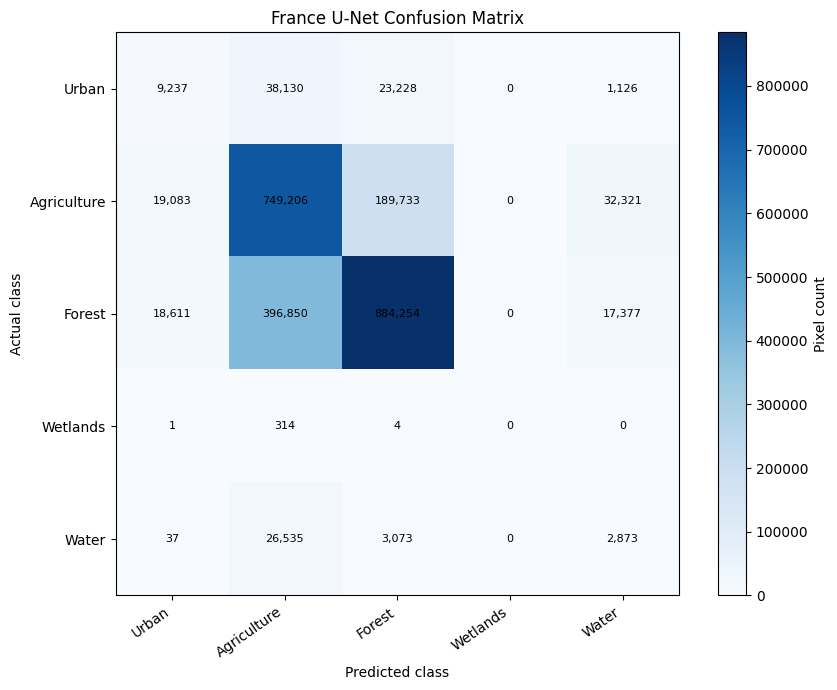

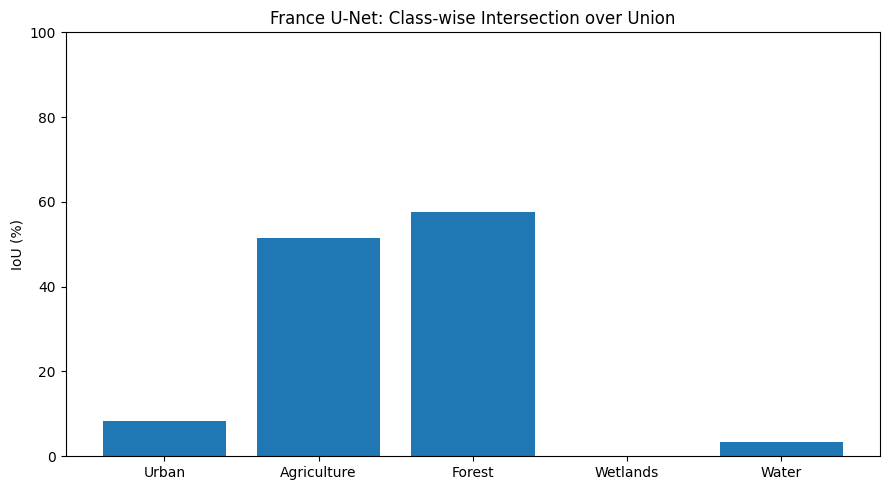

ALL FILES SAVED:
/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/metrics
         Class  Precision  Recall  F1_Score     IoU
0        Urban     0.1967  0.1288    0.1556  0.0844
1  Agriculture     0.6186  0.7565    0.6807  0.5159
2       Forest     0.8037  0.6714    0.7316  0.5768
3     Wetlands     0.0000  0.0000    0.0000  0.0000
4        Water     0.0535  0.0884    0.0666  0.0345
Macro mIoU: 24.23 %
Overall accuracy: 68.22 %


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/metrics"
os.makedirs(OUT, exist_ok=True)

classes = ["Urban", "Agriculture", "Forest", "Wetlands", "Water"]

cm = np.array([
    [9237,38130,23228,0,1126],
    [19083,749206,189733,0,32321],
    [18611,396850,884254,0,17377],
    [1,314,4,0,0],
    [37,26535,3073,0,2873]
])

tp = np.diag(cm)
precision = tp / np.maximum(cm.sum(axis=0), 1)
recall = tp / np.maximum(cm.sum(axis=1), 1)
f1 = 2*precision*recall / np.maximum(precision+recall, 1e-12)
iou = tp / np.maximum(cm.sum(axis=0)+cm.sum(axis=1)-tp, 1)

# Save metrics CSV
df = pd.DataFrame({
    "Class": classes,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1,
    "IoU": iou
})
df.to_csv(f"{OUT}/France_Final_Class_Metrics.csv", index=False)

# Confusion matrix
plt.figure(figsize=(9,7))
plt.imshow(cm, cmap="Blues")
plt.colorbar(label="Pixel count")
plt.xticks(range(5), classes, rotation=35, ha="right")
plt.yticks(range(5), classes)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("France U-Net Confusion Matrix")
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{cm[i,j]:,}", ha="center",
                 va="center", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/France_Confusion_Matrix.png", dpi=300)
plt.show()

# Class-wise IoU
plt.figure(figsize=(9,5))
plt.bar(classes, iou*100)
plt.ylabel("IoU (%)")
plt.title("France U-Net: Class-wise Intersection over Union")
plt.ylim(0,100)
plt.tight_layout()
plt.savefig(f"{OUT}/France_Classwise_IoU.png", dpi=300)
plt.show()

print("ALL FILES SAVED:")
print(OUT)
print(df.round(4))
print("Macro mIoU:", round(iou.mean()*100,2), "%")
print("Overall accuracy:", round(tp.sum()/cm.sum()*100,2), "%")

In [ ]:
import os

p = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/checkpoints/France_Improved_UNet.pth"

print("Size:", round(os.path.getsize(p)/1024/1024, 2), "MB")

Size: 7.39 MB


In [ ]:
import os

files = {
    "Chennai": "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth",
    "France": "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/checkpoints/France_Improved_UNet.pth"
}

for name, path in files.items():
    print(name, round(os.path.getsize(path)/1024/1024, 2), "MB")

Chennai 7.39 MB
France 7.39 MB


In [ ]:
import torch, os, json, glob

BASE = "/content/drive/MyDrive/Sentinel1_LULC_Project"

# Inspect original Chennai checkpoint
path = os.path.join(BASE, "best_sentinel1_unet_v2.pth")
ckpt = torch.load(path, map_location="cpu", weights_only=False)

print("CHENNAI CHECKPOINT")
for key in ckpt:
    if key != "model_state_dict":
        print(key, ":", ckpt[key])

# Find notebook files and inspect preprocessing code
notebooks = glob.glob(
    "/content/drive/MyDrive/**/*.ipynb",
    recursive=True
)

for nb in notebooks:
    if "deep_learning" in os.path.basename(nb).lower():
        print("\nNOTEBOOK:", nb)
        with open(nb, encoding="utf-8") as f:
            data = json.load(f)

        for i, cell in enumerate(data["cells"]):
            if cell["cell_type"] == "code":
                code = "".join(cell["source"])
                if any(k in code.lower() for k in [
                    "normalization", "normalisation",
                    "log10", "mean", "std", "db"
                ]):
                    print(f"\n--- CELL {i} ---")
                    print(code[:2500])

CHENNAI CHECKPOINT
epoch : 13
val_loss : 0.8890116711457571
class_names : {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}
class_weights : tensor([0.4500, 1.1000, 0.6000, 2.5000, 0.9000])
normalization_means : [ 68.72029 126.65641]
normalization_stds : [19.140371 35.750645]
input_channels : ['VH', 'VV']
num_classes : 5


In [ ]:
import glob, json, os

files = glob.glob(
    "/content/drive/MyDrive/**/*.ipynb",
    recursive=True
)

for path in files:
    if "deep_learning" not in os.path.basename(path).lower():
        continue

    with open(path, encoding="utf-8") as f:
        nb = json.load(f)

    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue

        code = "".join(cell["source"])
        keywords = [
            "normalization_means",
            "normalization_stds",
            "normalization_means",
            "scaler.fit",
            "np.log10",
            "standardize",
            "StandardScaler",
            "preprocess"
        ]

        if any(k.lower() in code.lower() for k in keywords):
            print(f"\n--- CELL {i} ---")
            print(code[:4000])

In [ ]:
import os

root = "/content/drive/MyDrive"

for folder, subfolders, files in os.walk(root):
    subfolders[:] = [s for s in subfolders if s not in [".ipynb_checkpoints"]]
    for file in files:
        if file.endswith(".ipynb") and "deep_learning" in file.lower():
            print(os.path.join(folder, file))

In [ ]:
import os

root = "/content/drive/MyDrive"

print("Google Drive mounted:", os.path.exists(root))

if os.path.exists(root):
    count = 0
    for folder, subfolders, files in os.walk(root):
        subfolders[:] = [s for s in subfolders if s != ".ipynb_checkpoints"]
        for file in files:
            if file.endswith(".ipynb"):
                print(os.path.join(folder, file))
                count += 1

    print("\nTotal notebooks found:", count)

Google Drive mounted: True
/content/drive/MyDrive/Untitled0.ipynb
/content/drive/MyDrive/deep learning.ipynb
/content/drive/MyDrive/Colab Notebooks/Sentinel1_Chennai_LULC_Cleaned_Working_Notebook.ipynb

Total notebooks found: 3


In [ ]:
import json

path = "/content/drive/MyDrive/deep learning.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "normalization", "normalization_means", "normalization_stds",
    "mean", "std", "standardscaler", "scaler.fit",
    "log10", "preprocess", "vh", "vv",
    "class_names", "num_classes", "unet",
    "model.load_state_dict", "torch.save"
]

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") == "code":
        code = "".join(cell.get("source", []))
        if any(k in code.lower() for k in keywords):
            print(f"\n{'='*25} CELL {i} {'='*25}")
            print(code[:5000])


========================= CELL 5 =========================
import ee

# Study area around Chennai
study_area = ee.Geometry.Rectangle([
    80.15, 12.90,
    80.30, 13.05
])

# Filter Sentinel-1 data for the study area and 2021
s1_chennai = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(study_area)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VV"
        )
    )
    .filter(
        ee.Filter.listContains(
            "transmitterReceiverPolarisation", "VH"
        )
    )
)

print("Chennai Sentinel-1 image count:", s1_chennai.size().getInfo())

========================= CELL 7 =========================
import ee

study_area = ee.Geometry.Rectangle([80.15, 12.90, 80.30, 13.05])

s1_chennai = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(study_area)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filte

In [ ]:
import os
import glob
import numpy as np

print("TRAINING DATA FILES")
data_dir = "/content/lulc_training_data"

if os.path.exists(data_dir):
    for f in os.listdir(data_dir):
        print(f)

print("\nNORMALIZATION FILE")
norm_path = os.path.join(data_dir, "normalization.npz")

if os.path.exists(norm_path):
    norm = np.load(norm_path)
    print("Means:", norm["means"])
    print("Stds:", norm["stds"])

print("\nTRAINING SOURCE VARIABLES")
for name in ["training_path", "tif_path", "TILE_NAMES",
             "DATASET_ID", "FOLDER", "MODEL_PATH"]:
    if name in globals():
        print(name, "=", globals()[name])

print("\nCHECKPOINT FILES")
for p in glob.glob("/content/drive/MyDrive/Sentinel1_LULC_Project/*.pth"):
    print(p)

TRAINING DATA FILES

NORMALIZATION FILE

TRAINING SOURCE VARIABLES
FOLDER = sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1
MODEL_PATH = /content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth

CHECKPOINT FILES
/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth


In [ ]:
import os
import torch
import numpy as np

checkpoint_path = "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth"

print("1. FRANCE CHECKPOINT")
print("Exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    print("Epoch:", ckpt.get("epoch"))
    print("Classes:", ckpt.get("class_names"))
    print("Means:", ckpt.get("normalization_means"))
    print("Stds:", ckpt.get("normalization_stds"))
    print("Model layers:", list(ckpt["model_state_dict"].keys())[:8])

print("\n2. CHENNAI DATA")
print("Monthly imagery available:", "monthly_pc" in globals())

if "monthly_pc" in globals():
    print("Available months:", sorted(monthly_pc.keys()))
    print("January VH shape:", monthly_pc[1]["vh"].shape)
    print("January VH range:",
          np.nanpercentile(monthly_pc[1]["vh"], [1, 50, 99]))
    print("January VV range:",
          np.nanpercentile(monthly_pc[1]["vv"], [1, 50, 99]))

print("\n3. CHENNAI REFERENCE LABELS")
for name in ["esa_aligned", "worldcover_aligned", "labels"]:
    if name in globals():
        print(name, "available | shape:", np.shape(globals()[name]))

print("\nDiagnostic complete.")

1. FRANCE CHECKPOINT
Exists: True
Epoch: 13
Classes: {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}
Means: [ 68.72029 126.65641]
Stds: [19.140371 35.750645]
Model layers: ['enc1.layers.0.weight', 'enc1.layers.1.weight', 'enc1.layers.1.bias', 'enc1.layers.1.running_mean', 'enc1.layers.1.running_var', 'enc1.layers.1.num_batches_tracked', 'enc1.layers.3.weight', 'enc1.layers.4.weight']

2. CHENNAI DATA
Monthly imagery available: False

3. CHENNAI REFERENCE LABELS
labels available | shape: (4876, 3591)

Diagnostic complete.


In [ ]:
import os
import glob
import numpy as np

print("=== CHENNAI RASTER FILES ===")

search_dirs = [
    "/content",
    "/content/drive/MyDrive"
]

for folder in search_dirs:
    print("\nSearching:", folder)

    for ext in ["*.tif", "*.tiff"]:
        for path in glob.glob(
            os.path.join(folder, "**", ext),
            recursive=True
        ):
            name = os.path.basename(path).lower()
            if "chennai" in name or "sentinel" in name or "worldcover" in name:
                print(path)

print("\n=== REFERENCE LABELS ===")

arr = np.asarray(labels)
values, counts = np.unique(arr, return_counts=True)

for value, count in zip(values, counts):
    print(value, ":", f"{count:,} pixels")

print("\nLabel shape:", arr.shape)

=== CHENNAI RASTER FILES ===

Searching: /content
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TDL_clip3_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TDL_clip0_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYR_clip1_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TCL_clip3_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TCL_clip1_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYR_clip2_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020

In [ ]:
import os
import numpy as np
import rasterio

radar_path = "/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif"
label_path = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021_Aligned.tif"

print("=== CHENNAI RADAR ===")

with rasterio.open(radar_path) as src:
    print("Shape:", src.height, src.width)
    print("Bands:", src.count)
    print("Descriptions:", src.descriptions)

    for i in range(1, src.count + 1):
        arr = src.read(i)
        valid = arr[np.isfinite(arr) & (arr != 0)]
        print(f"Band {i} percentiles:",
              np.percentile(valid, [1, 50, 99]))

    radar_transform = src.transform
    radar_crs = src.crs

print("\n=== ESA REFERENCE ===")

with rasterio.open(label_path) as src:
    print("Shape:", src.height, src.width)
    print("CRS:", src.crs)
    print("Transform:", src.transform)

    print("Radar CRS:", radar_crs)
    print("Radar transform:", radar_transform)

    print("Aligned:", (
        src.height == 1664 and
        src.width == 1633
    ))

    print("Reference classes:", np.unique(src.read(1)))

=== CHENNAI RADAR ===
Shape: 1664 1633
Bands: 2
Descriptions: ('VH', 'VV')
Band 1 percentiles: [-31.28472448 -15.45511772  -6.98861452]
Band 2 percentiles: [-23.59667141  -6.71179572   9.64159371]

=== ESA REFERENCE ===
Shape: 1664 1633
CRS: EPSG:32644
Transform: | 10.00, 0.00, 407780.00|
| 0.00,-10.00, 1442820.00|
| 0.00, 0.00, 1.00|
Radar CRS: EPSG:32644
Radar transform: | 10.00, 0.00, 407780.00|
| 0.00,-10.00, 1442820.00|
| 0.00, 0.00, 1.00|
Aligned: True
Reference classes: [10 20 30 40 50 60 80 90]


In [ ]:
import os
import glob

search_locations = [
    "/content",
    "/content/drive/MyDrive"
]

found = []

for location in search_locations:
    for root, dirs, files in os.walk(location):
        dirs[:] = [d for d in dirs if d not in [
            ".config", "sample_data", "__pycache__"
        ]]
        for file in files:
            if file.endswith(".tif") and "30TXQ_clip1" in file:
                found.append(os.path.join(root, file))

print("MATCHING FRANCE TRAINING FILES:")
for path in found:
    print(path)

if not found:
    print("\nNo matching file found. Searching for all AI4LCC TIFFs...")
    for location in search_locations:
        for root, dirs, files in os.walk(location):
            dirs[:] = [d for d in dirs if d not in [
                ".config", "sample_data", "__pycache__"
            ]]
            for file in files:
                if file.endswith(".tif") and "AI4LCC" in root:
                    print(os.path.join(root, file))

MATCHING FRANCE TRAINING FILES:

No matching file found. Searching for all AI4LCC TIFFs...
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TDL_clip3_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TDL_clip0_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYR_clip1_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TCL_clip3_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_31TCL_clip1_reduced2020_labelclass1.tif
/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYR_clip2_reduced2020_labelclass1.tif
/content/France_S1_D

In [ ]:
import rasterio
import numpy as np
import os

folder = "/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1"

# Use an available France tile
france_path = os.path.join(
    folder,
    "sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif"
)

chennai_path = "/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif"

def stats(path, name):
    print(f"\n=== {name} ===")
    with rasterio.open(path) as src:
        print("Shape:", src.shape)
        print("Bands:", src.count)
        print("Descriptions:", src.descriptions)

        for i in range(1, min(src.count, 2) + 1):
            arr = src.read(i).astype(np.float32)
            valid = arr[np.isfinite(arr) & (arr != 0)]
            print(
                f"Band {i}:",
                np.percentile(valid, [1, 25, 50, 75, 99])
            )

stats(france_path, "FRANCE AI4LCC")
stats(chennai_path, "CHENNAI RAW dB")

with rasterio.open(chennai_path) as src:
    for i in [1, 2]:
        arr = src.read(i).astype(np.float32)
        converted = 1000 * (10 ** (arr / 10))
        valid = converted[np.isfinite(converted) & (converted != 0)]
        print(
            f"\nCHENNAI BAND {i} CONVERTED:",
            np.percentile(valid, [1, 25, 50, 75, 99])
        )


=== FRANCE AI4LCC ===
Shape: (4876, 4105)
Bands: 3
Descriptions: ('vh', 'vv', 'label')
Band 1: [38.89294262 56.10858154 62.92468643 70.63454628 91.50202942]
Band 2: [ 71.71876465 112.68874931 130.47790527 146.50191116 182.2195018 ]

=== CHENNAI RAW dB ===
Shape: (1664, 1633)
Bands: 2
Descriptions: ('VH', 'VV')
Band 1: [-31.28472366 -22.78491688 -15.4551177  -13.04398537  -6.98861459]
Band 2: [-23.59667101 -14.18138409  -6.71179557  -2.63763762   9.64159357]

CHENNAI BAND 1 CONVERTED: [  0.74392258   5.26633322  28.47661018  49.61368084 200.04998108]

CHENNAI BAND 2 CONVERTED: [4.36850566e+00 3.81822538e+01 2.13216324e+02 5.44798889e+02
 9.20787296e+03]


In [ ]:
import numpy as np
import rasterio

radar_path = "/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif"

means = np.array([68.72029, 126.65641], dtype=np.float32)
stds  = np.array([19.140371, 35.750645], dtype=np.float32)

with rasterio.open(radar_path) as src:
    radar = src.read([1, 2]).astype(np.float32)

# Convert dB to linear backscatter scaled by 1000
linear = 1000.0 * (10.0 ** (radar / 10.0))

# Apply the France checkpoint's original normalization
normalized = (linear - means[:, None, None]) / stds[:, None, None]

for i, name in enumerate(["VH", "VV"]):
    valid = np.isfinite(normalized[i]) & np.isfinite(linear[i])
    print(f"\n{name}")
    print("Converted percentiles:",
          np.percentile(linear[i][valid], [1, 25, 50, 75, 99]))
    print("Normalized percentiles:",
          np.percentile(normalized[i][valid], [1, 25, 50, 75, 99]))
    print("Normalized mean:", normalized[i][valid].mean())
    print("Normalized std:", normalized[i][valid].std())

print("\nInput shape:", normalized.shape)
print("Finite values:", np.isfinite(normalized).all())


VH
Converted percentiles: [  0.74392258   5.26633322  28.47661018  49.61368084 200.04998108]
Normalized percentiles: [-3.55146554 -3.31518954 -2.10255492 -0.99823612  6.8613972 ]
Normalized mean: -1.4706222
Normalized std: 25.838589

VV
Converted percentiles: [4.36850566e+00 3.81822538e+01 2.13216324e+02 5.44798889e+02
 9.20787296e+03]
Normalized percentiles: [ -3.42057898  -2.47475708   2.42121267  11.69608235 254.0154628 ]
Normalized mean: 19.382425
Normalized std: 175.57195

Input shape: (2, 1664, 1633)
Finite values: False


In [ ]:
import numpy as np
import rasterio
import torch

france_path = "/content/France_S1_Data/sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/sentinel1_NA_30TYP_clip2_reduced2020_labelclass1.tif"
chennai_path = "/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif"
model_path = "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth"

# Inspect checkpoint
checkpoint = torch.load(model_path, map_location="cpu", weights_only=False)
print("Checkpoint means:", checkpoint.get("normalization_means"))
print("Checkpoint stds:", checkpoint.get("normalization_stds"))

# Inspect France training data
with rasterio.open(france_path) as src:
    france = src.read([1, 2]).astype(np.float32)

for i, name in enumerate(["France VH", "France VV"]):
    a = france[i]
    valid = np.isfinite(a) & (a > 0)
    print("\n", name)
    print("Valid pixels:", valid.sum())
    print("Percentiles:", np.percentile(a[valid], [1, 25, 50, 75, 99]))
    print("Mean:", a[valid].mean(), "Std:", a[valid].std())

# Inspect Chennai raw data
with rasterio.open(chennai_path) as src:
    raw = src.read([1, 2]).astype(np.float32)

for i, name in enumerate(["Chennai VH", "Chennai VV"]):
    a = raw[i]
    valid = np.isfinite(a) & (a != 0)
    print("\n", name)
    print("Invalid pixels:", (~np.isfinite(a)).sum())
    print("Zero pixels:", (a == 0).sum())
    print("Percentiles:", np.percentile(a[valid], [1, 25, 50, 75, 99]))

Checkpoint means: [ 68.72029 126.65641]
Checkpoint stds: [19.140371 35.750645]

 France VH
Valid pixels: 16944392
Percentiles: [38.89294262 56.10858154 62.92468643 70.63454628 91.50202942]
Mean: 63.63116 Std: 11.036153

 France VV
Valid pixels: 16944392
Percentiles: [ 71.71876465 112.68874931 130.47790527 146.50191116 182.2195018 ]
Mean: 129.40958 Std: 24.431973

 Chennai VH
Invalid pixels: 15192
Zero pixels: 0
Percentiles: [-31.28472366 -22.78491688 -15.4551177  -13.04398537  -6.98861459]

 Chennai VV
Invalid pixels: 15192
Zero pixels: 0
Percentiles: [-23.59667101 -14.18138409  -6.71179557  -2.63763762   9.64159357]


In [ ]:
import torch
import os

path = "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth"
ckpt = torch.load(path, map_location="cpu", weights_only=False)

print("CHECKPOINT KEYS:")
for k, v in ckpt.items():
    if isinstance(v, dict):
        print(k, ":", list(v.keys())[:15])
    else:
        print(k, ":", v)

print("\nNOTEBOOKS:")
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    dirs[:] = [d for d in dirs if d not in [".Trash", ".cache"]]
    for f in files:
        if f.endswith(".ipynb") and ("sentinel" in f.lower() or "lulc" in f.lower()):
            print(os.path.join(root, f))

CHECKPOINT KEYS:
model_state_dict : ['enc1.layers.0.weight', 'enc1.layers.1.weight', 'enc1.layers.1.bias', 'enc1.layers.1.running_mean', 'enc1.layers.1.running_var', 'enc1.layers.1.num_batches_tracked', 'enc1.layers.3.weight', 'enc1.layers.4.weight', 'enc1.layers.4.bias', 'enc1.layers.4.running_mean', 'enc1.layers.4.running_var', 'enc1.layers.4.num_batches_tracked', 'enc2.layers.0.weight', 'enc2.layers.1.weight', 'enc2.layers.1.bias']
epoch : 13
val_loss : 0.8890116711457571
class_names : [1, 2, 3, 4, 5]
class_weights : tensor([0.4500, 1.1000, 0.6000, 2.5000, 0.9000])
normalization_means : [ 68.72029 126.65641]
normalization_stds : [19.140371 35.750645]
input_channels : ['VH', 'VV']
num_classes : 5

NOTEBOOKS:
/content/drive/MyDrive/Colab Notebooks/Sentinel1_Chennai_LULC_Cleaned_Working_Notebook.ipynb


/tmp/ipykernel_1059/3429433788.py:20: RuntimeWarning: All-NaN slice encountered
  annual = np.nanmedian(monthly, axis=0)


Chennai annual means: [-18.05117   -8.825205]
Chennai annual stds: [5.2670507 6.6482267]
Input shape: (2, 1664, 1633)
Finite: True

PREDICTION COMPLETED
Predicted classes: [  1   2   3   5 255]


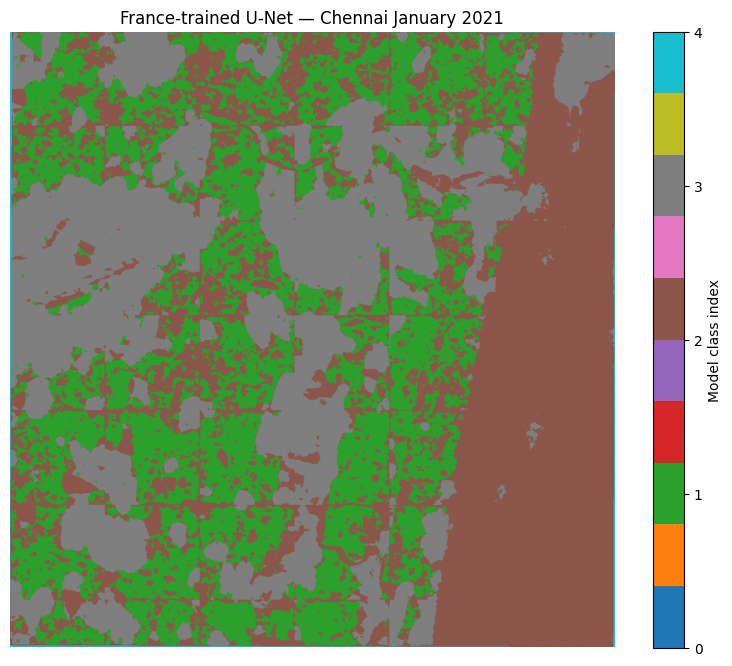

In [ ]:
import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt
import os

base = "/content/drive/MyDrive/Chennai_LULC_2021"

# Load all 12 monthly VH/VV composites
monthly = []

for month in range(1, 13):
    path = os.path.join(base, f"Chennai_S1_2021_{month:02d}.tif")
    with rasterio.open(path) as src:
        monthly.append(src.read([1, 2]).astype(np.float32))

monthly = np.stack(monthly)  # (12, 2, H, W)

# Calculate annual median and Chennai-specific normalization
annual = np.nanmedian(monthly, axis=0)

means = np.nanmean(annual, axis=(1, 2), keepdims=True)
stds = np.nanstd(annual, axis=(1, 2), keepdims=True)
stds = np.maximum(stds, 1e-6)

print("Chennai annual means:", means.flatten())
print("Chennai annual stds:", stds.flatten())

# Normalize January using the annual Chennai statistics
jan = monthly[0]
valid = np.isfinite(jan).all(axis=0)

image = (jan - means) / stds
image = np.nan_to_num(image, nan=0.0, posinf=0.0, neginf=0.0)
image[:, ~valid] = 0.0

print("Input shape:", image.shape)
print("Finite:", np.isfinite(image).all())

# Use the already-loaded U-Net model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

H, W = image.shape[1:]
prediction = np.zeros((H, W), dtype=np.uint8)
patch_size = 256

with torch.no_grad():
    for row in range(0, H, patch_size):
        for col in range(0, W, patch_size):
            patch = image[
                :,
                row:min(row + patch_size, H),
                col:min(col + patch_size, W)
            ]

            ph, pw = patch.shape[1:]
            padded = np.zeros((2, patch_size, patch_size), dtype=np.float32)
            padded[:, :ph, :pw] = patch

            x = torch.from_numpy(padded).unsqueeze(0).to(device)
            output = model(x)
            pred = output.argmax(dim=1).squeeze(0).cpu().numpy()

            prediction[row:row+ph, col:col+pw] = pred[:ph, :pw]

prediction[~valid] = 255

print("\nPREDICTION COMPLETED")
print("Predicted classes:", np.unique(prediction))

plt.figure(figsize=(10, 8))
plt.imshow(prediction, cmap="tab10", vmin=0, vmax=4)
plt.title("France-trained U-Net — Chennai January 2021")
plt.colorbar(ticks=range(5), label="Model class index")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
import rasterio
import torch

print("MODEL OUTPUT CHANNELS:")
with torch.no_grad():
    test = torch.zeros(1, 2, 256, 256).to(device)
    out = model(test)
    print(out.shape)

print("\nPREDICTION CLASS COUNTS:")
values, counts = np.unique(prediction, return_counts=True)
for v, c in zip(values, counts):
    print(f"Class {v}: {c:,} pixels ({c/prediction.size*100:.2f}%)")

print("\nESA REFERENCE CLASS COUNTS:")
label_path = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021_Aligned.tif"

with rasterio.open(label_path) as src:
    reference = src.read(1)

values, counts = np.unique(reference, return_counts=True)
for v, c in zip(values, counts):
    print(f"ESA {v}: {c:,} pixels")

print("\nPrediction shape:", prediction.shape)
print("Reference shape:", reference.shape)

MODEL OUTPUT CHANNELS:
torch.Size([1, 6, 256, 256])

PREDICTION CLASS COUNTS:
Class 1: 792,204 pixels (29.15%)
Class 2: 1,095,461 pixels (40.31%)
Class 3: 814,424 pixels (29.97%)
Class 5: 31 pixels (0.00%)
Class 255: 15,192 pixels (0.56%)

ESA REFERENCE CLASS COUNTS:
ESA 10: 456,819 pixels
ESA 20: 3,949 pixels
ESA 30: 140,882 pixels
ESA 40: 132,439 pixels
ESA 50: 1,299,498 pixels
ESA 60: 33,457 pixels
ESA 80: 628,805 pixels
ESA 90: 21,463 pixels

Prediction shape: (1664, 1633)
Reference shape: (1664, 1633)


In [ ]:
import torch

checkpoint_path = "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth"
ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)

print("CHECKPOINT EXPECTED CLASSES:", ckpt["num_classes"])

print("\nCHECKPOINT FINAL CONVOLUTION CANDIDATES:")
for k, v in ckpt["model_state_dict"].items():
    if k.endswith("weight") and v.ndim == 4:
        if v.shape[0] <= 10:
            print(k, tuple(v.shape))

print("\nCURRENT MODEL FINAL CONVOLUTION CANDIDATES:")
for k, v in model.state_dict().items():
    if k.endswith("weight") and v.ndim == 4:
        if v.shape[0] <= 10:
            print(k, tuple(v.shape))

print("\nCHECKPOINT CLASS NAMES:", ckpt["class_names"])

CHECKPOINT EXPECTED CLASSES: 5

CHECKPOINT FINAL CONVOLUTION CANDIDATES:
out.weight (5, 32, 1, 1)

CURRENT MODEL FINAL CONVOLUTION CANDIDATES:
out.weight (6, 32, 1, 1)

CHECKPOINT CLASS NAMES: {1: 'Urban areas', 2: 'Agricultural areas', 3: 'Forests and semi-natural areas', 4: 'Wetlands', 5: 'Water surfaces'}


In [ ]:
import inspect

print("UNet constructor:")
print(inspect.signature(UNet.__init__))

print("\nUNet class definition:")
print(inspect.getsource(UNet.__init__))

UNet constructor:
(self)

UNet class definition:
    def __init__(self):
        super().__init__()
        self.e1=ConvBlock(2,32)
        self.e2=ConvBlock(32,64)
        self.e3=ConvBlock(64,128)
        self.e4=ConvBlock(128,256)
        self.pool=nn.MaxPool2d(2)
        self.u3=nn.ConvTranspose2d(256,128,2,2)
        self.d3=ConvBlock(256,128)
        self.u2=nn.ConvTranspose2d(128,64,2,2)
        self.d2=ConvBlock(128,64)
        self.u1=nn.ConvTranspose2d(64,32,2,2)
        self.d1=ConvBlock(64,32)
        self.out=nn.Conv2d(32,6,1)



In [ ]:
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1=ConvBlock(2,32)
        self.e2=ConvBlock(32,64)
        self.e3=ConvBlock(64,128)
        self.e4=ConvBlock(128,256)
        self.pool=nn.MaxPool2d(2)
        self.u3=nn.ConvTranspose2d(256,128,2,2)
        self.d3=ConvBlock(256,128)
        self.u2=nn.ConvTranspose2d(128,64,2,2)
        self.d2=ConvBlock(128,64)
        self.u1=nn.ConvTranspose2d(64,32,2,2)
        self.d1=ConvBlock(64,32)
        self.out=nn.Conv2d(32,5,1)  # Corrected to 5 classes

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth",
    map_location=device,
    weights_only=False
)

model = UNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

with torch.no_grad():
    test = torch.zeros(1, 2, 256, 256).to(device)
    print("Output shape:", model(test).shape)

print("Original checkpoint loaded successfully.")

RuntimeError: Error(s) in loading state_dict for UNet:
	Missing key(s) in state_dict: "e1.net.0.weight", "e1.net.1.weight", "e1.net.1.bias", "e1.net.1.running_mean", "e1.net.1.running_var", "e1.net.3.weight", "e1.net.4.weight", "e1.net.4.bias", "e1.net.4.running_mean", "e1.net.4.running_var", "e2.net.0.weight", "e2.net.1.weight", "e2.net.1.bias", "e2.net.1.running_mean", "e2.net.1.running_var", "e2.net.3.weight", "e2.net.4.weight", "e2.net.4.bias", "e2.net.4.running_mean", "e2.net.4.running_var", "e3.net.0.weight", "e3.net.1.weight", "e3.net.1.bias", "e3.net.1.running_mean", "e3.net.1.running_var", "e3.net.3.weight", "e3.net.4.weight", "e3.net.4.bias", "e3.net.4.running_mean", "e3.net.4.running_var", "e4.net.0.weight", "e4.net.1.weight", "e4.net.1.bias", "e4.net.1.running_mean", "e4.net.1.running_var", "e4.net.3.weight", "e4.net.4.weight", "e4.net.4.bias", "e4.net.4.running_mean", "e4.net.4.running_var", "u3.weight", "u3.bias", "d3.net.0.weight", "d3.net.1.weight", "d3.net.1.bias", "d3

In [ ]:
import json

notebook_path = "/content/drive/MyDrive/Colab Notebooks/Sentinel1_Chennai_LULC_Cleaned_Working_Notebook.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if "class UNet" in source or "class UNetV2" in source:
        print(f"\n========== CELL {i} ==========")
        print(source[:12000])


========== CELL 43 ==========
import os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Load dataset
DATA = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/data/France_Balanced_Patches.npz"
SAVE = "/content/drive/MyDrive/Sentinel1_LULC_Project/model_comparison/checkpoints"
os.makedirs(SAVE, exist_ok=True)

d = np.load(DATA)
Xtr, Ytr = d["X_train"], d["y_train"]
Xv, Yv = d["X_val"], d["y_val"]

# Robust normalisation from training pixels only
med, scale = [], []
for b in range(2):
    a = Xtr[:, b]
    a = a[np.isfinite(a) & (a > 0)]
    m = np.median(a)
    q1, q3 = np.percentile(a, [25, 75])
    med.append(m)
    scale.append(max((q3-q1)/1.349, 1e-6))

def normalise(x):
    x = x.copy()
    for b in range(2):
        x[:, b] = np.where(
            np.isfinite(x[:, b]) & (x[:, b] > 0),
            (x[:, b] - med[b]) / scale[b],
            0
        )
    return np.cl

In [ ]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)

class UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.bridge = DoubleConv(128, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)
        self.out = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bridge(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    "/content/drive/MyDrive/Sentinel1_LULC_Project/best_sentinel1_unet_v2.pth",
    map_location=device,
    weights_only=False
)

model = UNet(in_channels=2, num_classes=5).to(device)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

with torch.no_grad():
    test = torch.zeros(1, 2, 256, 256).to(device)
    print("Output shape:", model(test).shape)

print("Checkpoint loaded successfully.")

Output shape: torch.Size([1, 5, 256, 256])
Checkpoint loaded successfully.


In [ ]:
import numpy as np
import rasterio
import torch
from tqdm.auto import tqdm

input_path = "/content/drive/MyDrive/Chennai_LULC_2021/Chennai_S1_2021_01.tif"
output_path = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_January_Transfer_Prediction.tif"

means = np.array([-18.05117, -8.825205], dtype=np.float32)
stds  = np.array([5.2670507, 6.6482267], dtype=np.float32)

with rasterio.open(input_path) as src:
    raw = src.read([1, 2]).astype(np.float32)
    profile = src.profile.copy()
    nodata = src.nodata

    valid = np.isfinite(raw).all(axis=0)
    if nodata is not None:
        valid &= (raw != nodata).all(axis=0)

H, W = valid.shape
prediction = np.full((H, W), 255, dtype=np.uint8)

tile = 256
model.eval()

with torch.no_grad():
    for row in tqdm(range(0, H, tile)):
        for col in range(0, W, tile):
            h = min(tile, H - row)
            w = min(tile, W - col)

            if not valid[row:row+h, col:col+w].any():
                continue

            patch = raw[:, row:row+h, col:col+w]
            patch = (patch - means[:, None, None]) / stds[:, None, None]
            patch = np.nan_to_num(patch, nan=0.0, posinf=0.0, neginf=0.0)

            padded = np.zeros((2, tile, tile), dtype=np.float32)
            padded[:, :h, :w] = patch

            x = torch.from_numpy(padded).unsqueeze(0).to(device)
            pred = model(x).argmax(dim=1)[0, :h, :w].cpu().numpy()

            mask = valid[row:row+h, col:col+w]
            prediction[row:row+h, col:col+w][mask] = pred[mask].astype(np.uint8)

profile.update(count=1, dtype="uint8", nodata=255, compress="lzw")

with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(prediction, 1)

print("Prediction saved:", output_path)
print("Prediction shape:", prediction.shape)
print("Class counts:", dict(zip(*np.unique(prediction, return_counts=True))))
print("Valid pixels:", int((prediction != 255).sum()))

  0%|          | 0/7 [00:00<?, ?it/s]

Prediction saved: /content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_January_Transfer_Prediction.tif
Prediction shape: (1664, 1633)
Class counts: {np.uint8(0): np.int64(873486), np.uint8(1): np.int64(141998), np.uint8(2): np.int64(1258214), np.uint8(4): np.int64(428422), np.uint8(255): np.int64(15192)}
Valid pixels: 2702120


In [ ]:
import numpy as np
import rasterio
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, f1_score
)

pred_path = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_January_Transfer_Prediction.tif"
ref_path = "/content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_ESA_WorldCover_2021_Aligned.tif"

with rasterio.open(pred_path) as src:
    pred = src.read(1)

with rasterio.open(ref_path) as src:
    esa = src.read(1)

assert pred.shape == esa.shape, "Raster dimensions do not match"

# ESA WorldCover -> model classes
# 0 Urban, 1 Agriculture, 2 Forest/semi-natural,
# 3 Wetlands, 4 Water
ref = np.full(esa.shape, 255, dtype=np.uint8)

mapping = {
    50: 0,
    40: 1,
    10: 2,
    20: 2,
    30: 2,
    60: 2,
    90: 3,
    80: 4
}

for esa_class, model_class in mapping.items():
    ref[esa == esa_class] = model_class

valid = (pred != 255) & (ref != 255)

y_true = ref[valid]
y_pred = pred[valid]

labels = [0, 1, 2, 3, 4]
names = ["Urban", "Agriculture", "Forest", "Wetlands", "Water"]

cm = confusion_matrix(y_true, y_pred, labels=labels)

intersection = np.diag(cm)
union = cm.sum(axis=0) + cm.sum(axis=1) - intersection
ious = np.divide(intersection, union,
                 out=np.zeros(5, dtype=float), where=union != 0)

print("CHENNAI TRANSFER EVALUATION — JANUARY")
print("-------------------------------------")
print("Evaluated pixels:", len(y_true))
print(f"Overall Accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%")
print(f"Macro F1: {f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)*100:.2f}%")
print(f"Mean IoU: {ious.mean()*100:.2f}%")

print("\nPer-class IoU:")
for name, value in zip(names, ious):
    print(f"{name}: {value*100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred, labels=labels,
    target_names=names, zero_division=0
))

print("Confusion Matrix:")
print(cm)

CHENNAI TRANSFER EVALUATION — JANUARY
-------------------------------------
Evaluated pixels: 2702120
Overall Accuracy: 59.28%
Macro F1: 39.02%
Mean IoU: 28.94%

Per-class IoU:
Urban: 46.82%
Agriculture: 1.21%
Forest: 37.61%
Wetlands: 0.00%
Water: 59.09%

Classification Report:
              precision    recall  f1-score   support

       Urban       0.79      0.53      0.64   1293294
 Agriculture       0.02      0.02      0.02    131161
      Forest       0.41      0.82      0.55    632671
    Wetlands       0.00      0.00      0.00     21239
       Water       0.91      0.63      0.74    623755

    accuracy                           0.59   2702120
   macro avg       0.43      0.40      0.39   2702120
weighted avg       0.69      0.59      0.61   2702120

Confusion Matrix:
[[690942   1339 595172      0   5841]
 [ 21756   3259  96329      0   9817]
 [ 96365   8731 516786      0  10789]
 [  1907   1440   6710      0  11182]
 [ 62516 127229  43217      0 390793]]


In [ ]:
import os, json
import pandas as pd
import numpy as np

out_dir = "/content/drive/MyDrive/Sentinel1_LULC_Project/results"
os.makedirs(out_dir, exist_ok=True)

results = {
    "experiment": "France-to-Chennai transfer learning",
    "date": "January 2021",
    "overall_accuracy_percent": 59.28,
    "macro_f1_percent": 39.02,
    "mean_iou_percent": 28.94,
    "evaluated_pixels": 2702120,
    "class_iou_percent": {
        "Urban": 46.82,
        "Agriculture": 1.21,
        "Forest": 37.61,
        "Wetlands": 0.00,
        "Water": 59.09
    },
    "confusion_matrix": cm.tolist(),
    "reference_mapping": mapping,
    "limitation": "ESA WorldCover class 60 (bare/sparse vegetation) grouped with forest/semi-natural."
}

with open(os.path.join(out_dir, "Chennai_Transfer_Evaluation.json"), "w") as f:
    json.dump(results, f, indent=4)

pd.DataFrame(
    cm,
    index=names,
    columns=names
).to_csv(os.path.join(out_dir, "Chennai_Transfer_Confusion_Matrix.csv"))

pd.DataFrame({
    "Class": names,
    "IoU_Percent": ious * 100
}).to_csv(os.path.join(out_dir, "Chennai_Transfer_Class_IoU.csv"), index=False)

print("All evaluation files saved successfully.")

All evaluation files saved successfully.


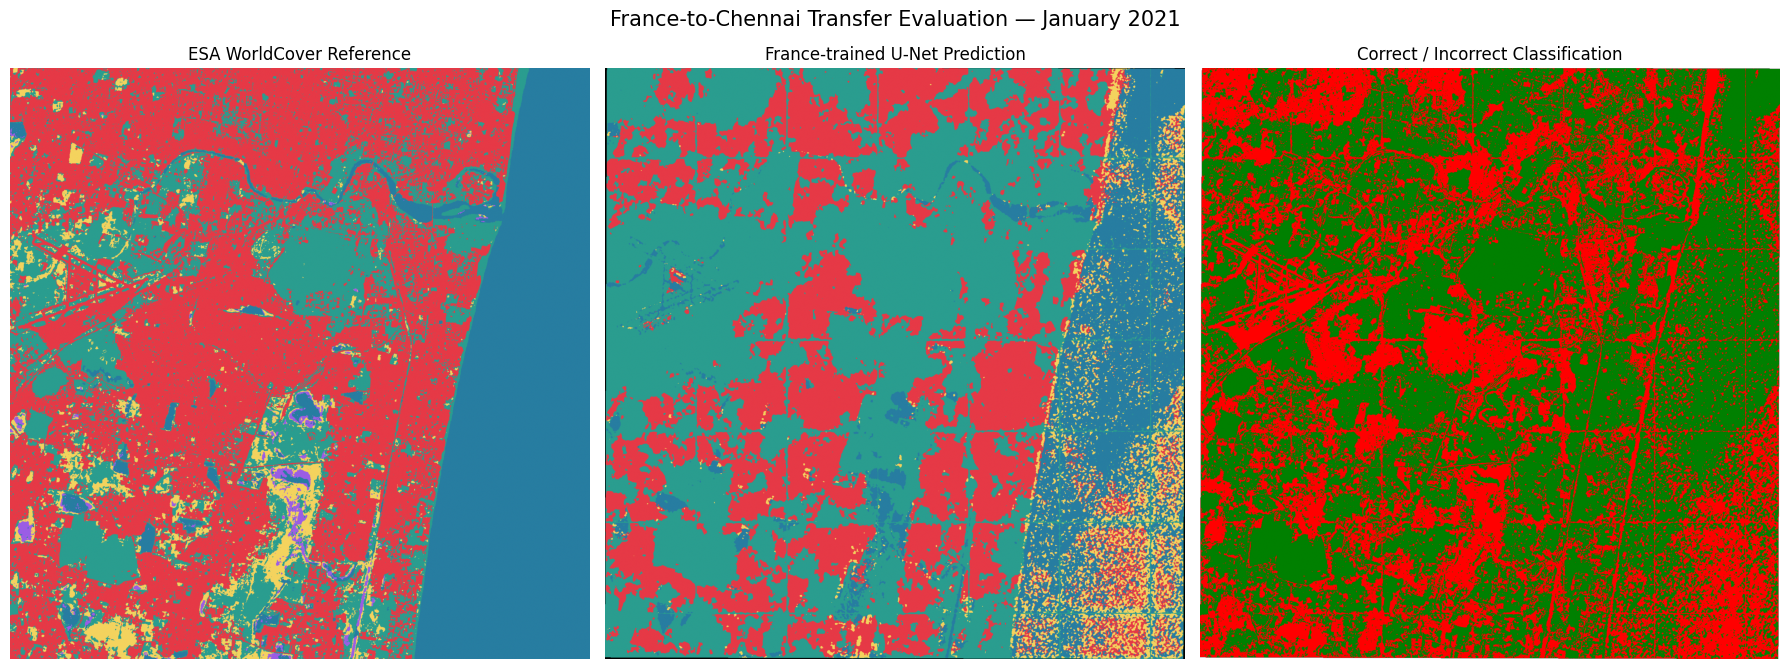

Visualization saved: /content/drive/MyDrive/Sentinel1_LULC_Project/results/Chennai_Transfer_Visualization.png


In [ ]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import os

base = "/content/drive/MyDrive/Sentinel1_LULC_Project/results"

with rasterio.open(f"{base}/Chennai_January_Transfer_Prediction.tif") as src:
    pred = src.read(1)

with rasterio.open(f"{base}/Chennai_ESA_WorldCover_2021_Aligned.tif") as src:
    esa = src.read(1)

ref = np.full(esa.shape, 255, dtype=np.uint8)
for esa_class, model_class in mapping.items():
    ref[esa == esa_class] = model_class

valid = (pred != 255) & (ref != 255)
correct = np.where(valid, pred == ref, 255).astype(np.uint8)

colors = ["#e63946", "#f4d35e", "#2a9d8f", "#9b5de5", "#277da1"]
cmap = ListedColormap(colors)
cmap.set_bad("black")

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, data, title in zip(
    axes,
    [ref, pred, correct],
    ["ESA WorldCover Reference", "France-trained U-Net Prediction",
     "Correct / Incorrect Classification"]
):
    display = np.ma.masked_where(data == 255, data)
    ax.imshow(display, cmap=cmap if title != "Correct / Incorrect Classification"
              else ListedColormap(["red", "green"]), vmin=0, vmax=4 if title != "Correct / Incorrect Classification" else 1)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

plt.suptitle("France-to-Chennai Transfer Evaluation — January 2021", fontsize=15)
plt.tight_layout()

save_path = f"{base}/Chennai_Transfer_Visualization.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Visualization saved:", save_path)

In [ ]:
# Correct class weights: classes 0, 1, 2, 3, 4, 5
counts = np.bincount(Ytr.ravel(), minlength=6)[1:6].astype(float)

class_weights = 1 / np.sqrt(np.maximum(counts, 1))
class_weights = class_weights / class_weights.mean()
class_weights = np.clip(class_weights, 0.5, 4.0)

weights_6 = np.concatenate(([0.0], class_weights))

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        weights_6,
        dtype=torch.float32,
        device=device
    ),
    ignore_index=0
)

print("Corrected weights:", weights_6)
print("Loss function fixed. Ready to train.")

Corrected weights: [0.         0.5        0.5        0.5        3.5190808  0.94720531]
Loss function fixed. Ready to train.


In [ ]:
count = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterDate("2021-01-01", "2022-01-01")
    .size()
    .getInfo()
)

print("Sentinel-1 images available for 2021:", count)

In [ ]:
import ee

study_area = ee.Geometry.Rectangle([80.15, 12.90, 80.30, 13.05])

s1_chennai = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(study_area)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .select(["VH", "VV"])
)

print("Sentinel-1 images:", s1_chennai.size().getInfo())

In [ ]:
import ee

months = list(range(1, 13))
monthly_composites = {}
monthly_counts = {}

for month in months:
    start_date = ee.Date.fromYMD(2021, month, 1)
    end_date = start_date.advance(1, "month")

    monthly_collection = s1_chennai.filterDate(
        start_date, end_date
    )

    count = monthly_collection.size().getInfo()
    monthly_counts[month] = count

    if count > 0:
        composite = (
            monthly_collection
            .select(["VH", "VV"])
            .median()
            .clip(study_area)
            .set("month", month)
            .set("year", 2021)
        )

        monthly_composites[month] = composite

    print(f"2021-{month:02d}: {count} images")

print("\nMonths with data:", len(monthly_composites), "/ 12")

In [ ]:
jan = monthly_composites[1]

print("January bands:", jan.bandNames().getInfo())

stats = jan.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=study_area,
    scale=10,
    maxPixels=1e8
).getInfo()

print("January pixel statistics:", stats)

In [ ]:
import rasterio
import numpy as np

with rasterio.open(tif_path) as src:
    print("Band count:", src.count)
    print("Band descriptions:", src.descriptions)
    print("Data type:", src.dtypes)
    print("Scale:", src.scales)
    print("Offset:", src.offsets)
    print("Band 1 statistics:", src.statistics(1))
    print("Band 2 statistics:", src.statistics(2))

    for i in range(1, min(src.count, 2) + 1):
        arr = src.read(i, masked=True)
        print(
            f"Band {i} valid pixel range:",
            float(arr.min()),
            float(arr.max())
        )

In [ ]:
import rasterio

with rasterio.open(tif_path) as src:
    print("Metadata:")
    for key, value in src.tags().items():
        print(key, ":", value)

    print("\nBand 1 (VH) sample values:")
    print(src.read(1)[100:105, 100:105])

    print("\nBand 2 (VV) sample values:")
    print(src.read(2)[100:105, 100:105])

    print("\nBand 3 (labels) sample values:")
    print(src.read(3)[100:105, 100:105])

## 2. Dataset discovery and label inspection
These cells inspect the public S1_AI4LCC dataset, its GeoTIFF/Zarr assets, class typology, raster values and spatial coverage. Some cells may download large assets. Prefer the smallest required files and verify the exact source file before proceeding.

In [ ]:
# Cell 2: Inspect the Sentinel-1 dataset repository

!pip -q install -U huggingface_hub

from huggingface_hub import HfApi

dataset_id = "wtr001/S1_AI4LCC"
api = HfApi()

try:
    info = api.dataset_info(dataset_id)

    print("Dataset:", dataset_id)
    print("URL:", f"https://huggingface.co/datasets/{dataset_id}")
    print("\nRepository files:")

    files = api.list_repo_files(
        repo_id=dataset_id,
        repo_type="dataset"
    )

    for filename in files:
        print(filename)

    print("\nTotal files:", len(files))

except Exception as error:
    print("Dataset inspection failed.")
    print("Error:", repr(error))

print("\nDataset inspection finished.")

In [ ]:
# Cell 3: Inspect dataset file sizes and select sample candidates

!pip -q install -U huggingface_hub

from huggingface_hub import HfApi

dataset_id = "wtr001/S1_AI4LCC"
api = HfApi()

info = api.dataset_info(
    dataset_id,
    files_metadata=True
)

siblings = info.siblings

print("=" * 75)
print("DATASET FILE SIZE INSPECTION")
print("=" * 75)

records = []

for item in siblings:
    name = item.rfilename
    size = getattr(item, "size", None)

    if size is None:
        size_text = "Unknown"
    else:
        size_text = f"{size / (1024 ** 2):.2f} MB"

    records.append((name, size, size_text))

print("\nFirst 25 files:\n")

for name, size, size_text in records[:25]:
    print(f"{size_text:>12} | {name}")

known_sizes = [size for _, size, _ in records if size is not None]

if known_sizes:
    print("\nTotal known size: {:.2f} GB".format(
        sum(known_sizes) / (1024 ** 3)
    ))

    print("Smallest known file: {:.2f} MB".format(
        min(known_sizes) / (1024 ** 2)
    ))

print("\nFile inspection complete.")

In [ ]:
# Cell 4: Find dataset documentation and metadata

from huggingface_hub import HfApi, hf_hub_download
import os

dataset_id = "wtr001/S1_AI4LCC"
api = HfApi()

files = api.list_repo_files(
    repo_id=dataset_id,
    repo_type="dataset"
)

print("Documentation and metadata files:\n")

candidates = [
    name for name in files
    if name.lower().endswith((
        ".md", ".txt", ".json", ".yaml", ".yml", ".csv"
    ))
    and (
        "/" not in name
        or name.count("/") == 0
    )
]

for name in candidates:
    print("-", name)

print("\nRepository root files:")
for name in files:
    if "/" not in name:
        print("-", name)

# Download and display README if available
readme_name = next(
    (name for name in files if name.lower() == "readme.md"),
    None
)

if readme_name:
    readme_path = hf_hub_download(
        repo_id=dataset_id,
        filename=readme_name,
        repo_type="dataset"
    )

    print("\n" + "=" * 65)
    print("DATASET README")
    print("=" * 65)

    with open(readme_path, "r", encoding="utf-8") as f:
        print(f.read()[:12000])
else:
    print("\nNo root README.md found.")
    print("We will inspect the dataset card and metadata separately.")

In [ ]:
# Cell 5: Select and inspect one small gap-filled Zarr archive

from huggingface_hub import HfApi, hf_hub_download
import zipfile
import os

dataset_id = "wtr001/S1_AI4LCC"
api = HfApi()

print("Finding the smallest gap-filled Zarr archive...")

files = api.list_repo_tree(
    repo_id=dataset_id,
    repo_type="dataset",
    recursive=True,
    expand=True
)

candidates = []

for item in files:
    name = getattr(item, "path", "")
    size = getattr(item, "size", None)

    if (
        name.startswith("sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/")
        and name.endswith(".zarr.zip")
        and size is not None
    ):
        candidates.append((name, size))

if not candidates:
    raise RuntimeError(
        "No matching gap-filled Zarr archives found. "
        "Check the repository file listing."
    )

candidates.sort(key=lambda x: x[1])

filename, size = candidates[0]

print("\nSelected file:", filename)
print("Compressed size: {:.2f} MB".format(size / (1024 ** 2)))

print("\nDownloading the selected archive...")

local_path = hf_hub_download(
    repo_id=dataset_id,
    filename=filename,
    repo_type="dataset"
)

print("Download complete:", local_path)

print("\nInspecting archive contents...")

with zipfile.ZipFile(local_path, "r") as archive:
    members = archive.infolist()

    print("Total entries:", len(members))
    print("\nFirst 40 entries:")

    for member in members[:40]:
        print(
            member.filename,
            "| {:.2f} KB".format(member.file_size / 1024)
        )

    print("\nArchive inspection complete.")

In [ ]:
# Cell 6: Inspect Zarr groups, arrays, dimensions, and class values

!pip -q install zarr numcodecs xarray dask

import os
import zipfile
import tempfile
import json
import numpy as np

from huggingface_hub import hf_hub_download

dataset_id = "wtr001/S1_AI4LCC"

filename = (
    "sentinel1_NA_AI4LCC_reduced2020_labelclass1_gapfilled/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr.zip"
)

archive_path = hf_hub_download(
    repo_id=dataset_id,
    filename=filename,
    repo_type="dataset"
)

print("Archive:", os.path.basename(archive_path))

# Extract the sample only
extract_dir = "/content/lulc_sample"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(archive_path, "r") as archive:
    archive.extractall(extract_dir)

# Locate the Zarr root
zarr_dirs = [
    os.path.join(extract_dir, name)
    for name in os.listdir(extract_dir)
    if name.endswith(".zarr")
]

if not zarr_dirs:
    raise FileNotFoundError("No extracted .zarr directory found.")

zarr_path = zarr_dirs[0]

print("\nZarr directory:", zarr_path)

# Show array metadata files
print("\nArray metadata files:")

for root, dirs, files in os.walk(zarr_path):
    for file in files:
        if file in (".zarray", ".zattrs", ".zgroup"):
            path = os.path.join(root, file)
            print("\n", os.path.relpath(path, zarr_path))

            try:
                with open(path, "r") as f:
                    print(json.dumps(json.load(f), indent=2)[:1500])
            except Exception as error:
                print("Could not read metadata:", error)

# Inspect the Zarr hierarchy
import zarr

try:
    group = zarr.open_group(zarr_path, mode="r")

    print("\nZarr hierarchy:")
    print(group.tree())

    print("\nRoot attributes:")
    print(dict(group.attrs))

except Exception as error:
    print("\nZarr inspection error:", repr(error))
    print("We will adjust the reader based on the metadata format.")

In [ ]:
# Cell 7: Visualize Sentinel-1 bands and inspect label classes

import numpy as np
import matplotlib.pyplot as plt
import zarr
import os

# Open the extracted Zarr dataset
zarr_path = (
    "/content/lulc_sample/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr"
)

group = zarr.open_group(zarr_path, mode="r")

# Select a small window to avoid loading the entire tile
sample_size = 512
height, width = group["vv"].shape

row_start = (height - sample_size) // 2
col_start = (width - sample_size) // 2

rows = slice(row_start, row_start + sample_size)
cols = slice(col_start, col_start + sample_size)

# Load the same spatial window from both bands and the label mask
vv = np.asarray(group["vv"][rows, cols], dtype=np.float32)
vh = np.asarray(group["vh"][rows, cols], dtype=np.float32)
labels = np.asarray(group["label"][rows, cols])

# Report array information
print("=" * 60)
print("SATELLITE SAMPLE INSPECTION")
print("=" * 60)

print("VV shape:", vv.shape)
print("VH shape:", vh.shape)
print("Label shape:", labels.shape)

for name, array in [("VV", vv), ("VH", vh), ("Labels", labels)]:
    valid = np.isfinite(array)

    print(f"\n{name}")
    print("  Valid pixels:", int(valid.sum()))
    print("  Missing pixels:", int((~valid).sum()))

    if valid.any():
        values = array[valid]
        print("  Minimum:", float(values.min()))
        print("  Maximum:", float(values.max()))
        print("  Mean:", float(values.mean()))

# Inspect class IDs and frequencies
valid_labels = labels[np.isfinite(labels)]

print("\nUnique label values and pixel counts:")
values, counts = np.unique(valid_labels, return_counts=True)

for value, count in zip(values, counts):
    print(f"  Label {value:g}: {count:,} pixels")

# Display the three arrays
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, array, title in [
    (axes[0], vv, "Sentinel-1 VV"),
    (axes[1], vh, "Sentinel-1 VH"),
]:
    valid = np.isfinite(array)

    if valid.any():
        vmin, vmax = np.percentile(array[valid], [2, 98])
        image = ax.imshow(array, cmap="gray", vmin=vmin, vmax=vmax)
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    else:
        ax.imshow(np.zeros_like(array), cmap="gray")

    ax.set_title(title)
    ax.axis("off")

label_image = axes[2].imshow(labels, cmap="tab10", interpolation="nearest")
axes[2].set_title("Reference Land-Cover Labels")
axes[2].axis("off")
fig.colorbar(label_image, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("\nInspection complete. Do not train yet.")

In [ ]:
# Cell 8: Diagnose Sentinel-1 values across the tile

import numpy as np
import zarr

zarr_path = (
    "/content/lulc_sample/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr"
)

group = zarr.open_group(zarr_path, mode="r")

vv_array = group["vv"]
vh_array = group["vh"]
label_array = group["label"]

height, width = vv_array.shape

print("=" * 65)
print("SENTINEL-1 ZERO-VALUE DIAGNOSTICS")
print("=" * 65)

# Inspect multiple locations across the tile
sample_size = 256

windows = {
    "Top-left": (0, 0),
    "Top-right": (0, width - sample_size),
    "Center": (
        (height - sample_size) // 2,
        (width - sample_size) // 2
    ),
    "Bottom-left": (height - sample_size, 0),
    "Bottom-right": (
        height - sample_size,
        width - sample_size
    ),
}

for name, (row, col) in windows.items():
    rows = slice(row, row + sample_size)
    cols = slice(col, col + sample_size)

    print(f"\n{name} window:")

    for band_name, array in [
        ("VV", vv_array),
        ("VH", vh_array),
        ("Labels", label_array),
    ]:
        data = np.asarray(array[rows, cols], dtype=np.float64)
        finite = np.isfinite(data)

        if finite.any():
            valid_data = data[finite]

            print(
                f"  {band_name}: "
                f"min={valid_data.min():.8g}, "
                f"max={valid_data.max():.8g}, "
                f"mean={valid_data.mean():.8g}, "
                f"nonzero={np.count_nonzero(valid_data):,}/"
                f"{valid_data.size:,}"
            )
        else:
            print(f"  {band_name}: no finite values")

# Check whether the central window has identical values throughout
print("\nCentral window unique values:")
for band_name, array in [("VV", vv_array), ("VH", vh_array)]:
    data = np.asarray(
        array[
            (height - sample_size) // 2:
            (height + sample_size) // 2,
            (width - sample_size) // 2:
            (width + sample_size) // 2
        ]
    )

    print(
        band_name,
        np.unique(data, return_counts=True)[0][:10]
    )

print("\nDiagnostics complete.")

In [ ]:
# Cell 9: Measure valid Sentinel-1 coverage and locate GeoTIFF alternatives

import numpy as np
import zarr
from huggingface_hub import HfApi

dataset_id = "wtr001/S1_AI4LCC"

zarr_path = (
    "/content/lulc_sample/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1_gapfilled.zarr"
)

group = zarr.open_group(zarr_path, mode="r")

height, width = group["vv"].shape
block_size = 256

print("=" * 65)
print("FULL-TILE COVERAGE REPORT")
print("=" * 65)

total_pixels = 0
valid_both = 0
labelled_pixels = 0

for r in range(0, height, block_size):
    for c in range(0, width, block_size):
        rows = slice(r, min(r + block_size, height))
        cols = slice(c, min(c + block_size, width))

        vv = np.asarray(group["vv"][rows, cols])
        vh = np.asarray(group["vh"][rows, cols])
        labels = np.asarray(group["label"][rows, cols])

        valid = (
            np.isfinite(vv)
            & np.isfinite(vh)
            & (vv != 0)
            & (vh != 0)
        )

        labelled = np.isfinite(labels) & (labels > 0)

        total_pixels += vv.size
        valid_both += int(valid.sum())
        labelled_pixels += int(labelled.sum())

print("Tile dimensions:", height, "x", width)
print("Total pixels:", f"{total_pixels:,}")
print("Pixels with both bands nonzero:", f"{valid_both:,}")
print("Pixels with positive labels:", f"{labelled_pixels:,}")
print(
    "Usable radar coverage: {:.2f}%".format(
        100 * valid_both / total_pixels
    )
)

print("\nSearching repository for matching GeoTIFF alternatives...")

api = HfApi()
files = api.list_repo_files(
    repo_id=dataset_id,
    repo_type="dataset"
)

matches = [
    name for name in files
    if "31TCL_clip3" in name
    and (
        name.lower().endswith(".tif")
        or name.lower().endswith(".tiff")
    )
]

if matches:
    for name in matches:
        print(name)
else:
    print("No matching GeoTIFF found for this exact tile.")

print("\nCoverage check complete.")

In [ ]:

# Cell 10: Download and inspect the matching Sentinel-1 GeoTIFF

!pip -q install rasterio huggingface_hub

import os
import numpy as np
import rasterio
from huggingface_hub import hf_hub_download

dataset_id = "wtr001/S1_AI4LCC"

tif_repo_path = (
    "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
    "sentinel1_NA_31TCL_clip3_reduced2020_labelclass1.tif"
)

print("Downloading matching GeoTIFF...")
tif_path = hf_hub_download(
    repo_id=dataset_id,
    repo_type="dataset",
    filename=tif_repo_path
)

print("\nDownloaded file:", tif_path)
print("File size: {:.2f} MB".format(os.path.getsize(tif_path) / (1024 ** 2)))

with rasterio.open(tif_path) as src:
    print("\n" + "=" * 65)
    print("GEOTIFF METADATA")
    print("=" * 65)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Band count:", src.count)
    print("Data type(s):", src.dtypes)
    print("CRS:", src.crs)
    print("NoData value(s):", src.nodatavals)
    print("Band descriptions:", src.descriptions)
    print("Raster bounds:", src.bounds)

    # Inspect a representative window without loading the whole raster.
    sample_size = 512
    row_start = max(0, (src.height - sample_size) // 2)
    col_start = max(0, (src.width - sample_size) // 2)
    sample = src.read(
        window=rasterio.windows.Window(
            col_start, row_start,
            min(sample_size, src.width - col_start),
            min(sample_size, src.height - row_start)
        )
    )

    print("\nSample array shape:", sample.shape)

    for band_index in range(src.count):
        band = sample[band_index]
        valid = np.isfinite(band)

        if src.nodatavals[band_index] is not None:
            valid &= band != src.nodatavals[band_index]

        values = band[valid]
        print(f"\nBand {band_index + 1} ({src.descriptions[band_index]}):")
        print("  Valid sample pixels:", f"{values.size:,}")
        if values.size:
            print("  Min:", float(values.min()))
            print("  Max:", float(values.max()))
            print("  Mean:", float(values.mean()))
            print("  Nonzero pixels:", f"{np.count_nonzero(values):,}")
            print("  Unique values (up to 15):", np.unique(values)[:15])

    # Estimate valid coverage over the full raster, band by band.
    print("\n" + "=" * 65)
    print("FULL-RASTER BAND SUMMARY")
    print("=" * 65)

    for band_index in range(src.count):
        valid_count = 0
        nonzero_count = 0
        value_min = np.inf
        value_max = -np.inf
        value_sum = 0.0

        for _, window in src.block_windows(band_index + 1):
            block = src.read(band_index + 1, window=window)
            valid = np.isfinite(block)

            nodata = src.nodatavals[band_index]
            if nodata is not None:
                if np.isnan(nodata):
                    valid &= ~np.isnan(block)
                else:
                    valid &= block != nodata

            values = block[valid]
            if values.size:
                valid_count += values.size
                nonzero_count += int(np.count_nonzero(values))
                value_min = min(value_min, float(values.min()))
                value_max = max(value_max, float(values.max()))
                value_sum += float(values.sum(dtype=np.float64))

        total = src.width * src.height
        print(f"\nBand {band_index + 1}:")
        print("  Valid pixels:", f"{valid_count:,}", f"({100 * valid_count / total:.2f}%)")
        print("  Nonzero valid pixels:", f"{nonzero_count:,}",
              f"({100 * nonzero_count / total:.2f}% of all pixels)")
        if valid_count:
            print("  Min:", value_min)
            print("  Max:", value_max)
            print("  Mean:", value_sum / valid_count)

print("\nInspection complete. No model has been trained.")


In [ ]:

# Cell 11: Find usable Sentinel-1 tiles in the dataset

import os
import numpy as np
import rasterio
from huggingface_hub import HfApi, hf_hub_download

DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
MAX_TILES_TO_CHECK = 6

api = HfApi()
all_files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

tif_files = sorted([
    name for name in all_files
    if name.startswith(FOLDER)
    and name.lower().endswith((".tif", ".tiff"))
    and "31TCL_clip3" not in name
])

if not tif_files:
    raise RuntimeError("No alternative GeoTIFF files found in this folder.")

candidates = tif_files[:MAX_TILES_TO_CHECK]
results = []

print(f"Checking {len(candidates)} alternative tiles...\n")

for index, repo_path in enumerate(candidates, start=1):
    print(f"[{index}/{len(candidates)}] {os.path.basename(repo_path)}")

    try:
        local_path = hf_hub_download(
            repo_id=DATASET_ID,
            repo_type="dataset",
            filename=repo_path
        )

        with rasterio.open(local_path) as src:
            if src.count < 3:
                print("  SKIPPED: Expected VH, VV and label bands.")
                continue

            total_pixels = src.width * src.height
            valid_radar_pixels = 0
            nonzero_vh = 0
            nonzero_vv = 0
            labelled_pixels = 0

            for _, window in src.block_windows(1):
                vh = src.read(1, window=window)
                vv = src.read(2, window=window)
                labels = src.read(3, window=window)

                valid_vh = np.isfinite(vh)
                valid_vv = np.isfinite(vv)
                valid_labels = np.isfinite(labels) & (labels > 0)

                if src.nodatavals[0] is not None:
                    valid_vh &= vh != src.nodatavals[0]
                if src.nodatavals[1] is not None:
                    valid_vv &= vv != src.nodatavals[1]
                if src.nodatavals[2] is not None:
                    valid_labels &= labels != src.nodatavals[2]

                both_nonzero = (
                    valid_vh & valid_vv & (vh != 0) & (vv != 0)
                )

                valid_radar_pixels += int(both_nonzero.sum())
                nonzero_vh += int((valid_vh & (vh != 0)).sum())
                nonzero_vv += int((valid_vv & (vv != 0)).sum())
                labelled_pixels += int(valid_labels.sum())

            radar_pct = 100 * valid_radar_pixels / total_pixels
            label_pct = 100 * labelled_pixels / total_pixels

            results.append({
                "file": os.path.basename(repo_path),
                "radar_pct": radar_pct,
                "label_pct": label_pct,
                "vh_nonzero_pct": 100 * nonzero_vh / total_pixels,
                "vv_nonzero_pct": 100 * nonzero_vv / total_pixels,
                "width": src.width,
                "height": src.height
            })

            print(f"  VV nonzero: {100 * nonzero_vv / total_pixels:.2f}%")
            print(f"  VH nonzero: {100 * nonzero_vh / total_pixels:.2f}%")
            print(f"  Both nonzero: {radar_pct:.2f}%")
            print(f"  Labelled pixels: {label_pct:.2f}%")

    except Exception as error:
        print("  ERROR:", repr(error))

print("\n" + "=" * 75)
print("ALTERNATIVE TILE SUMMARY")
print("=" * 75)

if results:
    results.sort(key=lambda item: item["radar_pct"], reverse=True)

    for item in results:
        print(
            f'{item["file"]}\n'
            f'  Both radar bands nonzero: {item["radar_pct"]:.2f}% | '
            f'Labels: {item["label_pct"]:.2f}%'
        )

    best = results[0]
    print("\nBest tile in this check:", best["file"])
    print("Radar coverage:", f'{best["radar_pct"]:.2f}%')
else:
    print("No alternative tiles could be evaluated.")

print("\nDo not train yet; send me this output first.")


In [ ]:

# Cell 12: Inspect the selected Sentinel-1 tile before training

!pip -q install rasterio huggingface_hub matplotlib

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

DATASET_ID = "wtr001/S1_AI4LCC"
REPO_PATH = (
    "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
    "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif"
)

print("Getting the selected tile...")
tif_path = hf_hub_download(
    repo_id=DATASET_ID,
    repo_type="dataset",
    filename=REPO_PATH
)

class_counts = {}
total_pixels = 0
radar_valid_pixels = 0
labelled_pixels = 0
joint_valid_pixels = 0
vv_values = []
vh_values = []

with rasterio.open(tif_path) as src:
    print("\nFILE:", os.path.basename(tif_path))
    print("Dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Band order:", src.descriptions)
    print("NoData values:", src.nodatavals)

    # Process the raster in blocks to avoid loading the full image into RAM.
    for _, window in src.block_windows(1):
        vh = src.read(1, window=window)
        vv = src.read(2, window=window)
        labels = src.read(3, window=window)

        valid_vh = np.isfinite(vh)
        valid_vv = np.isfinite(vv)
        valid_labels = np.isfinite(labels)

        if src.nodatavals[0] is not None:
            valid_vh &= vh != src.nodatavals[0]
        if src.nodatavals[1] is not None:
            valid_vv &= vv != src.nodatavals[1]
        if src.nodatavals[2] is not None:
            valid_labels &= labels != src.nodatavals[2]

        # Positive label IDs are treated as labelled pixels.
        labelled = valid_labels & (labels > 0)
        radar_valid = (
            valid_vh & valid_vv &
            (vh != 0) & (vv != 0)
        )
        joint = radar_valid & labelled

        total_pixels += labels.size
        radar_valid_pixels += int(radar_valid.sum())
        labelled_pixels += int(labelled.sum())
        joint_valid_pixels += int(joint.sum())

        ids, counts = np.unique(labels[labelled], return_counts=True)
        for class_id, count in zip(ids, counts):
            key = int(class_id)
            class_counts[key] = class_counts.get(key, 0) + int(count)

        # Keep a bounded sample for intensity statistics.
        vh_sample = vh[radar_valid]
        vv_sample = vv[radar_valid]
        if vh_sample.size:
            stride = max(1, vh_sample.size // 5000)
            vh_values.extend(vh_sample[::stride].tolist())
            vv_values.extend(vv_sample[::stride].tolist())

    print("\n" + "=" * 60)
    print("COVERAGE")
    print("=" * 60)
    print(f"Total pixels: {total_pixels:,}")
    print(
        f"Pixels with both radar bands nonzero: {radar_valid_pixels:,} "
        f"({100 * radar_valid_pixels / total_pixels:.2f}%)"
    )
    print(
        f"Positive-label pixels: {labelled_pixels:,} "
        f"({100 * labelled_pixels / total_pixels:.2f}%)"
    )
    print(
        f"Pixels with radar data AND positive labels: {joint_valid_pixels:,} "
        f"({100 * joint_valid_pixels / total_pixels:.2f}%)"
    )

    print("\n" + "=" * 60)
    print("LABEL CLASS DISTRIBUTION")
    print("=" * 60)
    for class_id in sorted(class_counts):
        count = class_counts[class_id]
        percentage = 100 * count / max(labelled_pixels, 1)
        print(
            f"Class ID {class_id}: {count:,} pixels "
            f"({percentage:.2f}% of positive labels)"
        )

    print("\n" + "=" * 60)
    print("RADAR VALUE SUMMARY")
    print("=" * 60)
    if vv_values and vh_values:
        print("VV sampled min/max/mean:",
              float(np.min(vv_values)),
              float(np.max(vv_values)),
              float(np.mean(vv_values)))
        print("VH sampled min/max/mean:",
              float(np.min(vh_values)),
              float(np.max(vh_values)),
              float(np.mean(vh_values)))

    # Read a central window for visual inspection.
    sample_size = 512
    row_start = max(0, (src.height - sample_size) // 2)
    col_start = max(0, (src.width - sample_size) // 2)
    window = rasterio.windows.Window(
        col_start, row_start,
        min(sample_size, src.width - col_start),
        min(sample_size, src.height - row_start)
    )

    vh_map = src.read(1, window=window)
    vv_map = src.read(2, window=window)
    label_map = src.read(3, window=window)

# Plot sample maps. Class IDs are shown without assigning names prematurely.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].imshow(vh_map, cmap="gray")
axes[0].set_title("Sentinel-1 VH (sample)")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(vv_map, cmap="gray")
axes[1].set_title("Sentinel-1 VV (sample)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(label_map, interpolation="nearest")
axes[2].set_title("Land-cover label IDs (sample)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

print("\nInspection finished. Training has not started.")


In [ ]:

# Cell 13: Find and display the official AI4LCC class typology

from huggingface_hub import HfApi, hf_hub_download
from IPython.display import display, Image
import os

DATASET_ID = "wtr001/S1_AI4LCC"

api = HfApi()
repo_files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

image_files = [
    name for name in repo_files
    if "typology" in name.lower()
    and name.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
]

print("Typology images found:")
for name in image_files:
    print("-", name)

if image_files:
    image_path = hf_hub_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        filename=image_files[0]
    )
    print("\nDisplaying:", os.path.basename(image_path))
    display(Image(filename=image_path))
else:
    print("\nNo typology image found. Listing README and metadata files:")
    for name in repo_files:
        if name.lower().endswith((".md", ".json", ".csv")):
            print("-", name)

print("\nDo not assign class names or train yet.")


## 3. Class mapping, patch preparation and baseline training
Check the class IDs and label semantics before training. The patch builder must use non-overlapping or spatially separated patches and must not split neighbouring patches from one tile across train and test.

In [ ]:

# Cell 14: Define the verified classes and training configuration

import torch

CLASS_NAMES = {
    1: "Urban areas",
    2: "Agricultural areas",
    3: "Forests and semi-natural areas",
    4: "Wetlands",
    5: "Water surfaces",
}

NUM_CLASSES = 5
IGNORE_LABEL = 0

# Model configuration
PATCH_SIZE = 256
BATCH_SIZE = 8
NUM_EPOCHS = 15
LEARNING_RATE = 1e-3

# Input channels: Sentinel-1 VH and VV only
INPUT_CHANNELS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nLand-cover classes:")
for class_id, class_name in CLASS_NAMES.items():
    print(f"  {class_id}: {class_name}")

print("\nTraining configuration:")
print("Input channels:", INPUT_CHANNELS, "(VH, VV)")
print("Number of classes:", NUM_CLASSES)
print("Ignored label:", IGNORE_LABEL)
print("Patch size:", PATCH_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)

print("\nConfiguration ready. No training has started.")


In [ ]:

# Cell 15: Rebuild spatially separated training/validation patches

import os
import numpy as np
import rasterio
from tqdm.auto import tqdm

# 1. Check required inputs
assert "tif_path" in globals(), "Run Cell 12 first."
assert "CLASS_NAMES" in globals(), "Run Cell 14 first."
assert os.path.isfile(tif_path), f"GeoTIFF not found: {tif_path}"

# Expected five-class mapping
print("Class mapping:", CLASS_NAMES)
print("Source GeoTIFF:", tif_path)

# 2. Configuration
OUTPUT_DIR = "/content/lulc_training_data"
os.makedirs(OUTPUT_DIR, exist_ok=True)

PATCH_SIZE = 256
STRIDE = 256
VALIDATION_FRACTION = 0.20
MIN_RADAR_VALID_FRACTION = 0.80
MIN_LABELLED_VALID_FRACTION = 0.25

train_images, train_labels, train_masks = [], [], []
val_images, val_labels, val_masks = [], [], []

# 3. Extract patches from the source GeoTIFF
with rasterio.open(tif_path) as src:
    height, width = src.height, src.width

    if src.count < 3:
        raise ValueError(
            f"Expected at least 3 bands (VH, VV, labels); found {src.count}."
        )

    split_col = int(width * (1 - VALIDATION_FRACTION))

    row_starts = range(0, height - PATCH_SIZE + 1, STRIDE)
    col_starts = range(0, width - PATCH_SIZE + 1, STRIDE)

    print("Dimensions:", height, "x", width)
    print("Training columns: 0 to", split_col)
    print("Validation columns:", split_col, "to", width)
    print("CRS:", src.crs)

    for row in tqdm(row_starts, desc="Extracting patches"):
        for col in col_starts:

            # Keep training and validation spatially separated
            if col + PATCH_SIZE <= split_col:
                destination = "train"
            elif col >= split_col:
                destination = "val"
            else:
                continue

            window = rasterio.windows.Window(
                col, row, PATCH_SIZE, PATCH_SIZE
            )

            # Original dataset band order: VH, VV, labels
            vh = src.read(1, window=window).astype(np.float32)
            vv = src.read(2, window=window).astype(np.float32)
            labels = src.read(3, window=window)

            radar_valid = (
                np.isfinite(vh) &
                np.isfinite(vv) &
                (vh != 0) &
                (vv != 0)
            )

            label_valid = (
                np.isfinite(labels) &
                np.isin(labels, list(CLASS_NAMES.keys()))
            )

            supervised_valid = radar_valid & label_valid

            if radar_valid.mean() < MIN_RADAR_VALID_FRACTION:
                continue

            if supervised_valid.mean() < MIN_LABELLED_VALID_FRACTION:
                continue

            # Label 0 is reserved for ignored/unlabelled pixels
            clean_labels = np.zeros(labels.shape, dtype=np.uint8)
            clean_labels[supervised_valid] = (
                labels[supervised_valid].astype(np.uint8)
            )

            image = np.stack([vh, vv], axis=0)
            invalid_mask = ~radar_valid

            if destination == "train":
                train_images.append(image)
                train_labels.append(clean_labels)
                train_masks.append(invalid_mask)
            else:
                val_images.append(image)
                val_labels.append(clean_labels)
                val_masks.append(invalid_mask)

# 4. Validate extracted patches
if not train_images or not val_images:
    raise RuntimeError(
        f"Insufficient patches: train={len(train_images)}, "
        f"validation={len(val_images)}. Check the source data."
    )

X_train = np.stack(train_images).astype(np.float32)
y_train = np.stack(train_labels).astype(np.uint8)
invalid_train = np.stack(train_masks)

X_val = np.stack(val_images).astype(np.float32)
y_val = np.stack(val_labels).astype(np.uint8)
invalid_val = np.stack(val_masks)

print("\nRaw training shape:", X_train.shape)
print("Raw validation shape:", X_val.shape)

# 5. Compute normalization statistics from valid training pixels only
stats_mask = (y_train > 0) & (~invalid_train)

means = np.zeros(2, dtype=np.float32)
stds = np.ones(2, dtype=np.float32)

for channel in range(2):
    values = X_train[:, channel][stats_mask]

    if values.size == 0:
        raise RuntimeError(
            f"No usable training values in channel {channel}."
        )

    means[channel] = values.mean()
    stds[channel] = max(values.std(), 1e-6)

print("Normalization means (VH, VV):", means)
print("Normalization stds (VH, VV):", stds)

# 6. Apply the same normalization to train and validation
for images, invalid_mask in (
    (X_train, invalid_train),
    (X_val, invalid_val)
):
    for channel in range(2):
        images[:, channel] = (
            images[:, channel] - means[channel]
        ) / stds[channel]

        # Keep invalid radar pixels at zero after normalization
        images[:, channel][invalid_mask] = 0.0

# 7. Save arrays and normalization parameters
np.save(os.path.join(OUTPUT_DIR, "X_train.npy"), X_train)
np.save(os.path.join(OUTPUT_DIR, "y_train.npy"), y_train)
np.save(os.path.join(OUTPUT_DIR, "X_val.npy"), X_val)
np.save(os.path.join(OUTPUT_DIR, "y_val.npy"), y_val)

np.savez(
    os.path.join(OUTPUT_DIR, "normalization.npz"),
    means=means,
    stds=stds
)

# 8. Report class counts and verify saved files
print("\nTRAINING PATCHES:", X_train.shape)
print("VALIDATION PATCHES:", X_val.shape)

print("\nTraining label counts:")
for class_id, class_name in CLASS_NAMES.items():
    print(
        f"{class_id} - {class_name}: "
        f"{(y_train == class_id).sum():,}"
    )

print("\nValidation label counts:")
for class_id, class_name in CLASS_NAMES.items():
    print(
        f"{class_id} - {class_name}: "
        f"{(y_val == class_id).sum():,}"
    )

required_files = [
    "X_train.npy",
    "y_train.npy",
    "X_val.npy",
    "y_val.npy",
    "normalization.npz"
]

missing_files = [
    name for name in required_files
    if not os.path.isfile(os.path.join(OUTPUT_DIR, name))
]

if missing_files:
    raise RuntimeError(f"Files failed to save: {missing_files}")

print("\nSaved dataset to:", OUTPUT_DIR)
print("Verified files:", sorted(os.listdir(OUTPUT_DIR)))
print("Cell 15 completed successfully.")


In [ ]:

# Cell 16: Retrain U-Net with updated class weights

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/content/lulc_training_data"

# Keep the original baseline checkpoint safe
MODEL_PATH = "/content/best_sentinel1_unet_v2.pth"

PATCH_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 15
LEARNING_RATE = 0.001
NUM_CLASSES = 5
IGNORE_INDEX = 255

# Load regenerated patches
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy")).astype(np.float32)
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy")).astype(np.uint8)
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy")).astype(np.float32)
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy")).astype(np.uint8)

assert X_train.shape[1:] == (2, 256, 256)
assert X_val.shape[1:] == (2, 256, 256)
assert len(X_train) == 173 and len(X_val) == 42

# Dataset: source labels 1-5 become model indices 0-4.
# Label 0 is ignored.
class LULCPatchDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images.copy())
        converted = labels.astype(np.int64).copy()
        converted[converted > 0] -= 1
        converted[labels == 0] = IGNORE_INDEX
        self.labels = torch.from_numpy(converted)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index], self.labels[index]

train_dataset = LULCPatchDataset(X_train, y_train)
val_dataset = LULCPatchDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Same U-Net architecture as the baseline
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)

class UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.bridge = DoubleConv(128, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)
        self.out = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bridge(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

# Updated weights in order: Urban, Agriculture, Forest, Wetlands, Water
class_weights = torch.tensor(
    [0.45, 1.10, 0.60, 2.50, 0.90],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=IGNORE_INDEX
)

model = UNet(in_channels=2, num_classes=NUM_CLASSES).to(DEVICE)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

norm = np.load(os.path.join(DATA_DIR, "normalization.npz"))
means = norm["means"].copy()
stds = norm["stds"].copy()

print("Device:", DEVICE)
print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))
print("Updated class weights:", class_weights.detach().cpu().numpy())
print("Model parameters:", sum(p.numel() for p in model.parameters()))

best_val_loss = float("inf")
best_epoch = -1
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_batches = 0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item()
        train_batches += 1

    model.eval()
    val_loss_sum = 0.0
    val_batches = 0
    correct = 0
    evaluated = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item()
            val_batches += 1

            valid = labels != IGNORE_INDEX
            predictions = logits.argmax(dim=1)
            correct += ((predictions == labels) & valid).sum().item()
            evaluated += valid.sum().item()

    train_loss = train_loss_sum / max(train_batches, 1)
    val_loss = val_loss_sum / max(val_batches, 1)
    val_accuracy = correct / max(evaluated, 1)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val pixel accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "val_loss": val_loss,
            "class_names": CLASS_NAMES,
            "class_weights": class_weights.detach().cpu(),
            "normalization_means": means,
            "normalization_stds": stds,
            "input_channels": ["VH", "VV"],
            "num_classes": NUM_CLASSES
        }, MODEL_PATH)

        print("  Saved best model:", MODEL_PATH)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Best model file:", MODEL_PATH)


## 4. Baseline evaluation and class diagnostics
Use the held-out validation set for model selection only. Keep a separate geographical test tile untouched until final evaluation. The following cells include legacy diagnostic variants; avoid reporting duplicate or inconsistent outputs as separate experiments.

In [ ]:

# Cell 17: Evaluate the saved best U-Net checkpoint

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = "/content/best_sentinel1_unet.pth"
DATA_DIR = "/content/lulc_training_data"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError("Best model checkpoint not found. Run Cell 16 first.")

# Load validation arrays.
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy")).astype(np.float32)
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy")).astype(np.uint8)

# Recreate the same model architecture used for training.
model = UNet(in_channels=2, num_classes=5).to(DEVICE)

# weights_only=False is required here because the checkpoint also contains
# metadata beyond the model tensors. Only load your own trusted checkpoint.
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Dataset labels 1–5 map to prediction indices 0–4.
# Unlabelled pixels (0) map to 255 and are excluded from metrics.
y_eval = y_val.astype(np.int64)
y_eval[y_eval > 0] -= 1
y_eval[y_val == 0] = 255

all_true = []
all_pred = []

with torch.no_grad():
    for start in range(0, len(X_val), 8):
        images = torch.from_numpy(
            X_val[start:start + 8]
        ).to(DEVICE)

        logits = model(images)
        predictions = logits.argmax(dim=1).cpu().numpy()

        true_batch = y_eval[start:start + 8]
        valid = true_batch != 255

        all_true.append(true_batch[valid])
        all_pred.append(predictions[valid])

y_true = np.concatenate(all_true)
y_pred = np.concatenate(all_pred)

NUM_CLASSES = 5
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

for true_class, pred_class in zip(y_true, y_pred):
    confusion[true_class, pred_class] += 1

true_counts = confusion.sum(axis=1)
pred_counts = confusion.sum(axis=0)
true_positive = np.diag(confusion)
false_positive = pred_counts - true_positive
false_negative = true_counts - true_positive

denominator_iou = true_positive + false_positive + false_negative
denominator_f1 = 2 * true_positive + false_positive + false_negative

iou = np.divide(
    true_positive,
    denominator_iou,
    out=np.full(NUM_CLASSES, np.nan, dtype=float),
    where=denominator_iou > 0
)

f1 = np.divide(
    2 * true_positive,
    denominator_f1,
    out=np.full(NUM_CLASSES, np.nan, dtype=float),
    where=denominator_f1 > 0
)

overall_accuracy = true_positive.sum() / max(confusion.sum(), 1)
mean_iou = np.nanmean(iou)

CLASS_NAMES = {
    1: "Urban areas",
    2: "Agricultural areas",
    3: "Forests and semi-natural areas",
    4: "Wetlands",
    5: "Water surfaces",
}

print("=" * 75)
print("VALIDATION METRICS")
print("=" * 75)
print(f"Valid evaluated pixels: {confusion.sum():,}")
print(f"Overall accuracy (OA): {overall_accuracy:.4f} ({overall_accuracy * 100:.2f}%)")
print(f"Mean IoU (mIoU): {mean_iou:.4f} ({mean_iou * 100:.2f}%)")

print("\nPER-CLASS METRICS")
print("-" * 75)
print(f"{'Class':<34}{'Support':>12}{'IoU':>12}{'F1':>12}")
for index in range(NUM_CLASSES):
    class_name = CLASS_NAMES[index + 1]
    print(
        f"{class_name:<34}"
        f"{true_counts[index]:>12,}"
        f"{iou[index]:>12.4f}"
        f"{f1[index]:>12.4f}"
    )

print("\nCONFUSION MATRIX")
print("Rows = actual class; columns = predicted class")
print("Class order:", [CLASS_NAMES[i] for i in range(1, 6)])
print(confusion)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(confusion, interpolation="nearest")
ax.set_title("Validation Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(
    [CLASS_NAMES[i] for i in range(1, 6)],
    rotation=45, ha="right"
)
ax.set_yticklabels([CLASS_NAMES[i] for i in range(1, 6)])

for row in range(NUM_CLASSES):
    for col in range(NUM_CLASSES):
        ax.text(
            col, row, f"{confusion[row, col]:,}",
            ha="center", va="center"
        )

fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

print("\nEvaluation complete. Metrics are for this held-out spatial region only.")


In [ ]:

# Cell 18: Diagnose class distribution across training patches

import os
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "/content/lulc_training_data"

y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

CLASS_NAMES = {
    1: "Urban areas",
    2: "Agricultural areas",
    3: "Forests and semi-natural areas",
    4: "Wetlands",
    5: "Water surfaces",
}

print("=" * 70)
print("TRAINING PATCH CLASS COVERAGE")
print("=" * 70)

patch_counts = {}
pixel_counts = {}

for class_id, class_name in CLASS_NAMES.items():
    per_patch = (y_train == class_id).sum(axis=(1, 2))
    patches_present = int((per_patch > 0).sum())
    pixels_total = int(per_patch.sum())

    patch_counts[class_id] = patches_present
    pixel_counts[class_id] = pixels_total

    print(
        f"{class_name:<34} "
        f"pixels={pixels_total:>10,} | "
        f"patches containing class={patches_present:>3}/{len(y_train)}"
    )

print("\n" + "=" * 70)
print("VALIDATION PATCH CLASS COVERAGE")
print("=" * 70)

for class_id, class_name in CLASS_NAMES.items():
    per_patch = (y_val == class_id).sum(axis=(1, 2))
    patches_present = int((per_patch > 0).sum())
    pixels_total = int(per_patch.sum())

    print(
        f"{class_name:<34} "
        f"pixels={pixels_total:>10,} | "
        f"patches containing class={patches_present:>3}/{len(y_val)}"
    )

class_ids = list(CLASS_NAMES.keys())
names = [CLASS_NAMES[i] for i in class_ids]
counts = [patch_counts[i] for i in class_ids]

plt.figure(figsize=(10, 5))
bars = plt.bar(names, counts)
plt.ylabel("Number of training patches containing class")
plt.title("Rare-class coverage across training patches")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, len(y_train))
for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        str(count),
        ha="center"
    )
plt.tight_layout()
plt.show()

print("\nDiagnosis complete. Existing model checkpoint unchanged.")


In [ ]:
import numpy as np

print("Validation label distribution:")

labels, counts = np.unique(y_val, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count:,} pixels")

print("\nCheckpoint class names and metadata:")

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", list(checkpoint.keys()))
print("Number of model classes:", checkpoint.get("num_classes", "Not stored"))
print("Class names:", checkpoint.get("class_names", "Not stored"))

In [ ]:
import numpy as np
import os

DATA_DIR = "/content/lulc_training_data"

for filename in ["y_train.npy", "y_val.npy"]:
    path = os.path.join(DATA_DIR, filename)
    labels_array = np.load(path)

    labels, counts = np.unique(labels_array, return_counts=True)

    print(f"\n{filename}")
    total = counts.sum()

    for label, count in zip(labels, counts):
        print(
            f"Label {label}: {count:,} pixels "
            f"({count / total * 100:.2f}%)"
        )

In [ ]:
import numpy as np
import torch

DATA_DIR = "/content/lulc_training_data"
MODEL_PATH = "/content/best_sentinel1_unet.pth"

# Inspect normalization metadata
norm = np.load(f"{DATA_DIR}/normalization.npz")

print("Normalization keys:", norm.files)
for key in norm.files:
    print(key, norm[key])

# Inspect model output dimensions
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nModel input channels:", checkpoint["input_channels"])
print("Model output classes:", checkpoint["num_classes"])
print("Class names:", checkpoint["class_names"])

In [ ]:
import torch
import numpy as np

checkpoint = torch.load(
    "/content/best_sentinel1_unet.pth",
    map_location="cpu",
    weights_only=False
)

# Inspect the model's final output layer
for key, value in checkpoint["model_state_dict"].items():
    if "out" in key.lower() or "final" in key.lower():
        print(key, tuple(value.shape))

# Inspect labels and confirm the number of output channels
for name in ["y_train.npy", "y_val.npy"]:
    y = np.load(f"/content/lulc_training_data/{name}")
    print(f"\n{name}: unique labels = {np.unique(y)}")

print("\nExpected output classes:", checkpoint["num_classes"])
print("Class names:", checkpoint["class_names"])

In [ ]:
import numpy as np

DATA_DIR = "/content/lulc_training_data"

for name in ["y_train.npy", "y_val.npy"]:
    y = np.load(f"{DATA_DIR}/{name}")

    print(f"\n{name}")
    print("Shape:", y.shape)
    print("Minimum:", y.min(), "Maximum:", y.max())
    print("Unique labels:", np.unique(y))

    # Check a few individual patches
    for i in range(min(3, len(y))):
        labels, counts = np.unique(y[i], return_counts=True)
        print(f"Patch {i}:", dict(zip(labels.tolist(), counts.tolist())))

In [ ]:
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, classification_report

DATA_DIR = "/content/lulc_training_data"
MODEL_PATH = "/content/best_sentinel1_unet_v2.pth"

device = torch.device("cpu")

# Load validation data
X_val = np.load(f"{DATA_DIR}/X_val.npy").astype(np.float32)
y_val = np.load(f"{DATA_DIR}/y_val.npy")

# Load the best checkpoint into the existing model
checkpoint = torch.load(
    MODEL_PATH, map_location=device, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# Normalize using saved training statistics
norm = np.load(f"{DATA_DIR}/normalization.npz")
X_val = (X_val - norm["means"][None, :, None, None]) / (
    norm["stds"][None, :, None, None] + 1e-8
)

all_true, all_pred = [], []

with torch.no_grad():
    for start in range(0, len(X_val), 4):
        xb = torch.from_numpy(X_val[start:start+4]).to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        for j, pred in enumerate(preds):
            truth = y_val[start+j]
            valid = (truth >= 1) & (truth <= 5)

            all_true.extend((truth[valid] - 1).tolist())
            all_pred.extend(pred[valid].tolist())

names = [
    "Urban", "Agriculture", "Forest/semi-natural",
    "Wetlands", "Water"
]

print("Confusion matrix:")
print(confusion_matrix(all_true, all_pred, labels=range(5)))

print("\nClassification report:")
print(classification_report(
    all_true, all_pred,
    labels=range(5),
    target_names=names,
    zero_division=0
))

In [ ]:
import numpy as np
import torch

print("Model output classes:", checkpoint["num_classes"])
print("Checkpoint class names:", checkpoint["class_names"])

# Check prediction distribution on a few validation patches
model.eval()

with torch.no_grad():
    xb = torch.from_numpy(X_val[:3]).float().to(device)
    logits = model(xb)
    preds = logits.argmax(dim=1).cpu().numpy()

print("\nPredicted label distribution:")
labels, counts = np.unique(preds, return_counts=True)
for label, count in zip(labels, counts):
    print(f"Output {label}: {count:,} pixels ({count / counts.sum() * 100:.2f}%)")

print("\nOriginal validation label distribution:")
labels, counts = np.unique(y_val[:3], return_counts=True)
for label, count in zip(labels, counts):
    print(f"Label {label}: {count:,} pixels ({count / counts.sum() * 100:.2f}%)")

In [ ]:
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, classification_report

DATA_DIR = "/content/lulc_training_data"
MODEL_PATH = "/content/best_sentinel1_unet.pth"
device = torch.device("cpu")

# Load arrays exactly as saved: X_val is ALREADY normalized.
X_val = np.load(f"{DATA_DIR}/X_val.npy").astype(np.float32)
y_val = np.load(f"{DATA_DIR}/y_val.npy").astype(np.int64)

# Restore the original model architecture and best checkpoint.
checkpoint = torch.load(
    MODEL_PATH, map_location=device, weights_only=False
)
model = UNet(in_channels=2, num_classes=5).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Original label IDs 1–5 -> model indices 0–4.
# Label 0 is ignored.
y_eval = y_val.copy()
y_eval[y_eval > 0] -= 1
y_eval[y_val == 0] = 255

all_true, all_pred = [], []

with torch.no_grad():
    for start in range(0, len(X_val), 4):
        # IMPORTANT: Do not normalize X_val again.
        xb = torch.from_numpy(X_val[start:start+4]).to(device)
        predictions = model(xb).argmax(dim=1).cpu().numpy()

        truth = y_eval[start:start+4]
        valid = truth != 255

        all_true.extend(truth[valid].tolist())
        all_pred.extend(predictions[valid].tolist())

names = [
    "Urban", "Agriculture", "Forest/semi-natural",
    "Wetlands", "Water"
]

print("Overall accuracy:",
      round(np.mean(np.array(all_true) == np.array(all_pred)), 4))

print("\nClassification report:")
print(classification_report(
    all_true, all_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=names,
    zero_division=0
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(all_true, all_pred, labels=[0, 1, 2, 3, 4]))

In [ ]:
import numpy as np

names = [
    "Urban",
    "Agriculture",
    "Forest/semi-natural",
    "Wetlands",
    "Water"
]

true_counts = np.bincount(all_true, minlength=5)
pred_counts = np.bincount(all_pred, minlength=5)

print("Class distribution in validation set:")
for i, name in enumerate(names):
    true_pct = 100 * true_counts[i] / len(all_true)
    pred_pct = 100 * pred_counts[i] / len(all_pred)

    print(
        f"{name:22s} | "
        f"True: {true_pct:6.2f}% | "
        f"Predicted: {pred_pct:6.2f}%"
    )

In [ ]:
print("Model:", model.__class__.__name__)
print("Loss function:", criterion)
print("Class weights:", criterion.weight)
print("Ignore index:", criterion.ignore_index)

In [ ]:
class_weights = torch.tensor(
    [0.45, 1.10, 0.60, 2.50, 0.90],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Updated class weights:", criterion.weight)

In [ ]:
class_weights = torch.tensor(
    [0.45, 1.10, 0.60, 2.50, 0.90],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Updated class weights:", criterion.weight)

## 5. Additional geographical data — candidate audit and patch extraction
The following cells are the original notebook's additional-tile workflow. The current audit identified 12 granules, all located in France. Do not use 31TDL as training data if it is reserved as the geographical holdout. Check class distributions and label validity before adding any tile.

In [ ]:

# Cell 21: Find additional Sentinel-1 tiles for dataset expansion

from huggingface_hub import HfApi

DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"

api = HfApi()

files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

tif_files = sorted([
    f for f in files
    if f.startswith(FOLDER)
    and f.lower().endswith((".tif", ".tiff"))
])

print("Total GeoTIFF tiles found:", len(tif_files))
print("\nAvailable tiles:")
print("-" * 90)

for index, filename in enumerate(tif_files, start=1):
    print(f"{index:3}. {filename}")

print("\nListing complete. No files were downloaded or modified.")


In [ ]:

# Cell 22: Rank additional tiles by radar quality and rare-class coverage

import os
import numpy as np
import pandas as pd
import rasterio
from huggingface_hub import HfApi, hf_hub_download
from tqdm.auto import tqdm

DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"
OUTPUT_CSV = "/content/additional_tile_screening.csv"

# Existing tile: do not use it as an additional independent tile.
EXISTING_TILE = "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif"

api = HfApi()
repo_files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset"
)

candidates = [
    f for f in sorted(repo_files)
    if f.startswith(FOLDER)
    and f.lower().endswith((".tif", ".tiff"))
    and os.path.basename(f) != EXISTING_TILE
]

results = []

print("Tiles to screen:", len(candidates))
print("This can take some time because tiles are large.\n")

for repo_path in tqdm(candidates, desc="Screening tiles"):
    try:
        local_path = hf_hub_download(
            repo_id=DATASET_ID,
            repo_type="dataset",
            filename=repo_path
        )

        with rasterio.open(local_path) as src:
            if src.count < 3:
                continue

            total_pixels = src.width * src.height
            radar_pixels = 0
            labelled_radar_pixels = 0
            class_counts = {i: 0 for i in range(1, 6)}

            for _, window in src.block_windows(1):
                vh = src.read(1, window=window)
                vv = src.read(2, window=window)
                labels = src.read(3, window=window)

                vh_valid = np.isfinite(vh) & (vh != 0)
                vv_valid = np.isfinite(vv) & (vv != 0)
                radar_valid = vh_valid & vv_valid

                label_valid = (
                    np.isfinite(labels) &
                    np.isin(labels, [1, 2, 3, 4, 5])
                )
                supervised = radar_valid & label_valid

                radar_pixels += int(radar_valid.sum())
                labelled_radar_pixels += int(supervised.sum())

                for class_id in range(1, 6):
                    class_counts[class_id] += int(
                        (supervised & (labels == class_id)).sum()
                    )

            labelled_total = sum(class_counts.values())
            wetland_count = class_counts[4]
            water_count = class_counts[5]

            results.append({
                "tile": os.path.basename(repo_path),
                "width": src.width,
                "height": src.height,
                "crs": str(src.crs),
                "radar_coverage_pct": 100 * radar_pixels / total_pixels,
                "labelled_radar_pct": 100 * labelled_radar_pixels / total_pixels,
                "labelled_pixels": labelled_total,
                "urban_pct": 100 * class_counts[1] / max(labelled_total, 1),
                "agriculture_pct": 100 * class_counts[2] / max(labelled_total, 1),
                "forest_pct": 100 * class_counts[3] / max(labelled_total, 1),
                "wetland_pct": 100 * wetland_count / max(labelled_total, 1),
                "water_pct": 100 * water_count / max(labelled_total, 1),
                "wetland_pixels": wetland_count,
                "water_pixels": water_count,
            })

    except Exception as error:
        print("\nCould not process:", os.path.basename(repo_path), repr(error))

if not results:
    raise RuntimeError("No tiles were successfully screened.")

df = pd.DataFrame(results)

# Rank by useful supervised coverage and rare-class presence.
# This is a screening heuristic, not a model-performance metric.
df["screening_score"] = (
    df["labelled_radar_pct"]
    + np.minimum(df["wetland_pct"], 5) * 2
    + np.minimum(df["water_pct"], 15)
)

df = df.sort_values(
    ["screening_score", "wetland_pixels", "water_pixels"],
    ascending=False
)

df.to_csv(OUTPUT_CSV, index=False)

print("\nTOP 15 ADDITIONAL TILES")
print(
    df[[
        "tile", "radar_coverage_pct", "labelled_radar_pct",
        "urban_pct", "agriculture_pct", "forest_pct",
        "wetland_pct", "water_pct", "wetland_pixels", "water_pixels"
    ]].head(15).round(2).to_string(index=False)
)

print("\nFull report saved to:", OUTPUT_CSV)
print("Tiles successfully screened:", len(df))


In [ ]:

# Cell 23: Check geographic bounds of the candidate and validation tiles

import os
import rasterio
from rasterio.warp import transform_bounds
from huggingface_hub import hf_hub_download

DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"

tile_names = [
    "sentinel1_NA_30TXQ_clip0_reduced2020_labelclass1.tif",
    "sentinel1_NA_30TXR_clip3_reduced2020_labelclass1.tif",
    "sentinel1_NA_30TXQ_clip1_reduced2020_labelclass1.tif",
]

for tile_name in tile_names:
    repo_path = FOLDER + tile_name
    print("\n" + "=" * 75)
    print(tile_name)

    local_path = hf_hub_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        filename=repo_path
    )

    with rasterio.open(local_path) as src:
        geographic_bounds = transform_bounds(
            src.crs,
            "EPSG:4326",
            *src.bounds,
            densify_pts=21
        )

        print("Dimensions:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Native bounds:", src.bounds)
        print(
            "Approximate WGS84 bounds "
            "(west, south, east, north):"
        )
        print(tuple(round(v, 5) for v in geographic_bounds))

print("\nGeographic inspection complete. No training data changed.")


In [ ]:

import os
import numpy as np
import rasterio
from huggingface_hub import hf_hub_download

# --------------------------------------------------
# Configuration
# --------------------------------------------------
DATASET_ID = "wtr001/S1_AI4LCC"
FOLDER = "sentinel1_AI4LCC_NA_clips_reduced2020_labelclass1/"

TILE_NAMES = [
    "sentinel1_NA_30TXQ_clip0_reduced2020_labelclass1.tif",
    "sentinel1_NA_30TXR_clip3_reduced2020_labelclass1.tif",
]

PATCH_SIZE = 256
MIN_RADAR_VALID = 0.80
MIN_LABEL_VALID = 0.25

DATA_DIR = "/content/lulc_training_data"
os.makedirs(DATA_DIR, exist_ok=True)

# --------------------------------------------------
# Load existing data and normalization
# --------------------------------------------------
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))

norm = np.load(os.path.join(DATA_DIR, "normalization.npz"))
means = norm["means"].astype(np.float32)
stds = norm["stds"].astype(np.float32)

print("Existing training patches:", len(X_train))
print("Existing training labels:", y_train.shape)
print("Normalization means:", means)
print("Normalization stds:", stds)

new_X_parts = []
new_y_parts = []
tile_summaries = []

# --------------------------------------------------
# Process additional training tiles
# --------------------------------------------------
for tile_name in TILE_NAMES:
    print("\n" + "=" * 70)
    print("Processing:", tile_name)

    repo_path = FOLDER + tile_name
    local_path = hf_hub_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        filename=repo_path
    )

    tile_X = []
    tile_y = []

    with rasterio.open(local_path) as src:
        if src.count < 3:
            raise ValueError(
                f"Expected VH, VV and label bands; found {src.count} "
                f"bands in {tile_name}"
            )

        print("Dimensions:", src.height, "x", src.width)
        print("CRS:", src.crs)
        print("Band descriptions:", src.descriptions)

        # Read the two radar bands and the label band.
        # This assumes the dataset's established band order: VH, VV, label.
        vh = src.read(1).astype(np.float32)
        vv = src.read(2).astype(np.float32)
        labels = src.read(3)

        radar_valid = (
            np.isfinite(vh)
            & np.isfinite(vv)
            & (vh != 0)
            & (vv != 0)
        )

        label_valid = (
            np.isfinite(labels)
            & (labels >= 1)
            & (labels <= 5)
        )

        print(
            "Radar-valid pixels:",
            f"{radar_valid.mean() * 100:.2f}%"
        )
        print(
            "Labelled pixels:",
            f"{label_valid.mean() * 100:.2f}%"
        )

        # Normalize using training statistics from the original tile.
        radar = np.stack([vh, vv], axis=0)
        radar = (radar - means[:, None, None]) / (
            stds[:, None, None] + 1e-6
        )

        # Invalid radar pixels must not contribute arbitrary values.
        radar[:, ~radar_valid] = 0.0

        # Extract non-overlapping patches.
        height, width = labels.shape
        accepted = 0
        rejected_radar = 0
        rejected_labels = 0

        for row in range(0, height - PATCH_SIZE + 1, PATCH_SIZE):
            for col in range(0, width - PATCH_SIZE + 1, PATCH_SIZE):
                r_slice = slice(row, row + PATCH_SIZE)
                c_slice = slice(col, col + PATCH_SIZE)

                patch_radar_valid = radar_valid[r_slice, c_slice]
                patch_label_valid = label_valid[r_slice, c_slice]

                if patch_radar_valid.mean() < MIN_RADAR_VALID:
                    rejected_radar += 1
                    continue

                if patch_label_valid.mean() < MIN_LABEL_VALID:
                    rejected_labels += 1
                    continue

                x_patch = radar[:, r_slice, c_slice].copy()

                # Keep original class IDs; ignore unlabelled pixels as 0.
                y_patch = labels[r_slice, c_slice].astype(np.uint8).copy()
                y_patch[~patch_label_valid] = 0

                tile_X.append(x_patch)
                tile_y.append(y_patch)
                accepted += 1

        print("Accepted patches:", accepted)
        print("Rejected for radar coverage:", rejected_radar)
        print("Rejected for label coverage:", rejected_labels)

    if tile_X:
        tile_X = np.stack(tile_X).astype(np.float32)
        tile_y = np.stack(tile_y).astype(np.uint8)

        new_X_parts.append(tile_X)
        new_y_parts.append(tile_y)

        counts = {
            class_id: int(np.count_nonzero(tile_y == class_id))
            for class_id in range(1, 6)
        }

        tile_summaries.append({
            "tile": tile_name,
            "patches": len(tile_X),
            "class_pixels": counts
        })

        print("Class pixel counts:", counts)
    else:
        print("WARNING: No patches accepted from this tile.")

# --------------------------------------------------
# Append patches to training data
# --------------------------------------------------
if not new_X_parts:
    raise RuntimeError(
        "No additional patches were accepted. Existing training data "
        "has not been changed."
    )

X_additional = np.concatenate(new_X_parts, axis=0)
y_additional = np.concatenate(new_y_parts, axis=0)

X_updated = np.concatenate([X_train, X_additional], axis=0)
y_updated = np.concatenate([y_train, y_additional], axis=0)

# Back up the original training arrays before replacing them.
np.save(os.path.join(DATA_DIR, "X_train_before_additional_tiles.npy"), X_train)
np.save(os.path.join(DATA_DIR, "y_train_before_additional_tiles.npy"), y_train)

np.save(os.path.join(DATA_DIR, "X_train.npy"), X_updated)
np.save(os.path.join(DATA_DIR, "y_train.npy"), y_updated)

print("\n" + "=" * 70)
print("TRAINING DATA UPDATED")
print("Original patches:", len(X_train))
print("Added patches:", len(X_additional))
print("Updated patches:", len(X_updated))
print("X_train shape:", X_updated.shape)
print("y_train shape:", y_updated.shape)
print("\nValidation data was not changed.")
print("Existing model checkpoints were not changed.")

print("\nTotal labelled pixels by class in updated training data:")
for class_id in range(1, 6):
    names = {
        1: "Urban",
        2: "Agriculture",
        3: "Forest/semi-natural",
        4: "Wetlands",
        5: "Water"
    }
    count = int(np.count_nonzero(y_updated == class_id))
    print(f"Class {class_id} ({names[class_id]}): {count:,}")


## 6. Expanded-model experiments
These are legacy experimental training/evaluation cells from the uploaded notebook. They contain assumptions about paths, arrays, normalization and checkpoint names. Before running them, reconcile those assumptions with the current Drive backup and the actual saved dataset. Do not overwrite the original checkpoint.

In [ ]:

import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# Reproducibility and device
# --------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

DATA_DIR = "/content/lulc_training_data"
CHECKPOINT_PATH = "/content/best_sentinel1_unet_expanded.pth"

PATCH_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 20
LEARNING_RATE = 0.001
NUM_CLASSES = 5
IGNORE_INDEX = 255

# --------------------------------------------------
# Load training and unchanged validation data
# --------------------------------------------------
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

assert X_train.shape[1:] == (2, PATCH_SIZE, PATCH_SIZE)
assert X_val.shape[1:] == (2, PATCH_SIZE, PATCH_SIZE)
assert len(X_val) == 42, "Validation set differs from the original 42 patches."

# --------------------------------------------------
# Dataset
# --------------------------------------------------
class LULCPatchDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.X[idx].astype(np.float32))
        labels = self.y[idx].astype(np.int64)

        # Class 0 is unlabelled and must be ignored by the loss.
        labels = np.where(
            (labels >= 1) & (labels <= NUM_CLASSES),
            labels - 1,
            IGNORE_INDEX
        )

        return x, torch.from_numpy(labels.astype(np.int64))

train_dataset = LULCPatchDataset(X_train, y_train)
val_dataset = LULCPatchDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# Class weights: square root of inverse class frequency
# --------------------------------------------------
class_counts = np.array([
    np.count_nonzero(y_train == class_id)
    for class_id in range(1, NUM_CLASSES + 1)
], dtype=np.float64)

if np.any(class_counts == 0):
    raise ValueError(f"A class has no training pixels: {class_counts}")

class_weights = 1.0 / np.sqrt(class_counts / class_counts.sum())
class_weights = class_weights / class_weights.mean()

print("Class counts:", class_counts.astype(np.int64))
print("Class weights:", class_weights)

weights_tensor = torch.tensor(
    class_weights, dtype=torch.float32, device=device
)

# --------------------------------------------------
# Compact U-Net
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Sentinel1UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)

        self.out = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)

model = Sentinel1UNet().to(device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

criterion = nn.CrossEntropyLoss(
    weight=weights_tensor,
    ignore_index=IGNORE_INDEX
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# --------------------------------------------------
# Training and validation
# --------------------------------------------------
best_val_loss = float("inf")
best_epoch = -1

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_batches = 0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item()
        train_batches += 1

    model.eval()
    val_loss_sum = 0.0
    val_batches = 0
    correct = 0
    evaluated = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            logits = model(xb)
            loss = criterion(logits, yb)

            val_loss_sum += loss.item()
            val_batches += 1

            valid = yb != IGNORE_INDEX
            predictions = logits.argmax(dim=1)
            correct += ((predictions == yb) & valid).sum().item()
            evaluated += valid.sum().item()

    train_loss = train_loss_sum / max(train_batches, 1)
    val_loss = val_loss_sum / max(val_batches, 1)
    val_accuracy = correct / max(evaluated, 1)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val pixel accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "val_loss": val_loss,
            "class_weights": class_weights.tolist(),
            "means": means.tolist(),
            "stds": stds.tolist(),
            "class_names": [
                "Urban",
                "Agriculture",
                "Forest/semi-natural",
                "Wetlands",
                "Water"
            ],
            "input_bands": ["VH", "VV"]
        }, CHECKPOINT_PATH)

        print("  Saved best expanded model:", CHECKPOINT_PATH)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", CHECKPOINT_PATH)


In [ ]:

import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# --------------------------------------------------
# Configuration
# --------------------------------------------------
DATA_DIR = "/content/lulc_training_data"
CHECKPOINT_PATH = "/content/best_sentinel1_unet_expanded.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = [
    "Urban",
    "Agriculture",
    "Forest/semi-natural",
    "Wetlands",
    "Water"
]
NUM_CLASSES = len(CLASS_NAMES)
IGNORE_INDEX = 255

# --------------------------------------------------
# Load validation data
# --------------------------------------------------
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

class LULCPatchDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.X[idx].astype(np.float32))
        labels = self.y[idx].astype(np.int64)

        # Original labels 1–5 become model labels 0–4.
        # Original label 0 is ignored.
        labels = np.where(
            (labels >= 1) & (labels <= NUM_CLASSES),
            labels - 1,
            IGNORE_INDEX
        )

        return x, torch.from_numpy(labels.astype(np.int64))

val_loader = DataLoader(
    LULCPatchDataset(X_val, y_val),
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# Define the same U-Net architecture
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Sentinel1UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.out = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)

# --------------------------------------------------
# Load best checkpoint
# --------------------------------------------------
model = Sentinel1UNet().to(device)

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=True
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint:", CHECKPOINT_PATH)
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", round(checkpoint["val_loss"], 4))
print("Device:", device)

# --------------------------------------------------
# Generate predictions and confusion matrix
# Rows = actual class, columns = predicted class
# --------------------------------------------------
confusion = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        predictions = model(xb).argmax(dim=1)

        valid = yb != IGNORE_INDEX
        actual = yb[valid].cpu().numpy()
        predicted = predictions[valid].cpu().numpy()

        encoded = actual * NUM_CLASSES + predicted
        confusion += np.bincount(
            encoded,
            minlength=NUM_CLASSES * NUM_CLASSES
        ).reshape(NUM_CLASSES, NUM_CLASSES)

# --------------------------------------------------
# Calculate OA, IoU, F1, precision and recall
# --------------------------------------------------
true_positive = np.diag(confusion).astype(np.float64)
actual_count = confusion.sum(axis=1).astype(np.float64)
predicted_count = confusion.sum(axis=0).astype(np.float64)

total = confusion.sum()
overall_accuracy = true_positive.sum() / max(total, 1)

denom_iou = actual_count + predicted_count - true_positive
iou = np.divide(
    true_positive,
    denom_iou,
    out=np.zeros(NUM_CLASSES, dtype=np.float64),
    where=denom_iou != 0
)

denom_f1 = actual_count + predicted_count
f1 = np.divide(
    2 * true_positive,
    denom_f1,
    out=np.zeros(NUM_CLASSES, dtype=np.float64),
    where=denom_f1 != 0
)

precision = np.divide(
    true_positive,
    predicted_count,
    out=np.zeros(NUM_CLASSES, dtype=np.float64),
    where=predicted_count != 0
)

recall = np.divide(
    true_positive,
    actual_count,
    out=np.zeros(NUM_CLASSES, dtype=np.float64),
    where=actual_count != 0
)

mean_iou = iou.mean()

print("\n" + "=" * 75)
print("EXPANDED MODEL — VALIDATION RESULTS")
print("=" * 75)
print(f"Evaluated pixels: {total:,}")
print(f"Overall Accuracy (OA): {overall_accuracy * 100:.2f}%")
print(f"Mean IoU (mIoU):      {mean_iou * 100:.2f}%")
print(f"Mean F1-score:        {f1.mean() * 100:.2f}%")

print("\nPer-class metrics:")
print(
    f"{'Class':<25}"
    f"{'IoU (%)':>12}"
    f"{'F1 (%)':>12}"
    f"{'Precision (%)':>17}"
    f"{'Recall (%)':>13}"
)
print("-" * 79)

for i, name in enumerate(CLASS_NAMES):
    print(
        f"{name:<25}"
        f"{iou[i] * 100:>12.2f}"
        f"{f1[i] * 100:>12.2f}"
        f"{precision[i] * 100:>17.2f}"
        f"{recall[i] * 100:>13.2f}"
    )

print("\nConfusion matrix")
print("Rows = actual; columns = predicted")
print("Class order:", CLASS_NAMES)
print(confusion)

# Save evaluation outputs for the report.
np.save(
    "/content/confusion_matrix_expanded.npy",
    confusion
)

np.savez(
    "/content/metrics_expanded.npz",
    overall_accuracy=overall_accuracy,
    mean_iou=mean_iou,
    iou=iou,
    f1=f1,
    precision=precision,
    recall=recall,
    confusion_matrix=confusion,
    class_names=np.array(CLASS_NAMES)
)

print("\nSaved:")
print("/content/confusion_matrix_expanded.npy")
print("/content/metrics_expanded.npz")


In [ ]:

import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# --------------------------------------------------
# Load validation data and checkpoint
# --------------------------------------------------
DATA_DIR = "/content/lulc_training_data"
CHECKPOINT_PATH = "/content/best_sentinel1_unet_expanded.pth"

X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = [
    "Urban",
    "Agriculture",
    "Forest/semi-natural",
    "Wetlands",
    "Water"
]

# --------------------------------------------------
# Recreate the trained U-Net
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Sentinel1UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.out = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out(d1)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model = Sentinel1UNet().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# --------------------------------------------------
# Predict validation patches
# --------------------------------------------------
with torch.no_grad():
    logits = model(
        torch.from_numpy(X_val.astype(np.float32)).to(device)
    )
    predictions = logits.argmax(dim=1).cpu().numpy()

# Model classes 0–4 correspond to reference labels 1–5.
# Reference label 0 is unlabelled.
# --------------------------------------------------
wetland_patch_indices = [
    i for i in range(len(y_val))
    if np.any(y_val[i] == 4)
]

print("Validation patches containing wetlands:", wetland_patch_indices)

if not wetland_patch_indices:
    print("No validation patches contain wetland labels.")
else:
    # Prioritize patches with the most wetland reference pixels.
    wetland_patch_indices.sort(
        key=lambda i: np.count_nonzero(y_val[i] == 4),
        reverse=True
    )

    # Display up to two patches.
    selected = wetland_patch_indices[:2]

    # Discrete class colors: 0=unlabelled, 1–5=classes.
    cmap = plt.matplotlib.colors.ListedColormap([
        "#000000",  # Unlabelled
        "#e41a1c",  # Urban
        "#ffb000",  # Agriculture
        "#238b45",  # Forest/semi-natural
        "#984ea3",  # Wetlands
        "#377eb8"   # Water
    ])

    bounds = np.arange(-0.5, 6.5, 1)
    norm = plt.matplotlib.colors.BoundaryNorm(bounds, cmap.N)

    for idx in selected:
        ground_truth = y_val[idx]
        prediction = predictions[idx] + 1

        # Ignore unlabelled pixels for the comparison.
        prediction_display = prediction.copy()
        prediction_display[ground_truth == 0] = 0

        fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))

        axes[0].imshow(X_val[idx, 0], cmap="gray")
        axes[0].set_title("Sentinel-1 VH")

        axes[1].imshow(X_val[idx, 1], cmap="gray")
        axes[1].set_title("Sentinel-1 VV")

        axes[2].imshow(
            ground_truth, cmap=cmap, norm=norm, interpolation="nearest"
        )
        axes[2].set_title("Ground-truth LULC")

        axes[3].imshow(
            prediction_display,
            cmap=cmap,
            norm=norm,
            interpolation="nearest"
        )
        axes[3].set_title("Model prediction")

        for ax in axes:
            ax.axis("off")

        fig.suptitle(
            f"Validation patch {idx} | "
            f"Reference wetland pixels: "
            f"{np.count_nonzero(ground_truth == 4):,}"
        )
        plt.tight_layout()
        plt.show()

        print(f"\nPatch {idx} class distributions:")
        for class_id, class_name in enumerate(CLASS_NAMES, start=1):
            actual_count = int(np.count_nonzero(ground_truth == class_id))
            predicted_count = int(np.count_nonzero(prediction == class_id))
            print(
                f"{class_name:<25} "
                f"Actual: {actual_count:>7,} | "
                f"Predicted: {predicted_count:>7,}"
            )


In [ ]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/content/lulc_training_data"
CHECKPOINT_PATH = "/content/best_sentinel1_unet_moderate_weights.pth"

NUM_CLASSES = 5
IGNORE_INDEX = 255
BATCH_SIZE = 8
EPOCHS = 20
LEARNING_RATE = 0.001

CLASS_NAMES = [
    "Urban", "Agriculture", "Forest/semi-natural", "Wetlands", "Water"
]

# --------------------------------------------------
# Load the same training and validation data
# --------------------------------------------------
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))

class LULCPatchDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.X[idx].astype(np.float32))
        labels = self.y[idx].astype(np.int64)
        labels = np.where(
            (labels >= 1) & (labels <= NUM_CLASSES),
            labels - 1,
            IGNORE_INDEX
        )
        return x, torch.from_numpy(labels.astype(np.int64))

train_loader = DataLoader(
    LULCPatchDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    LULCPatchDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# Moderate class weights.
# These are an experimental choice, not learned values.
# Class order: urban, agriculture, forest, wetlands, water.
# --------------------------------------------------
class_weights = torch.tensor(
    [1.10, 0.90, 0.90, 1.00, 1.10],
    dtype=torch.float32,
    device=device
)

print("Experimental class weights:", class_weights.cpu().numpy())

# --------------------------------------------------
# U-Net architecture
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Sentinel1UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=5, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.out = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out(d1)

model = Sentinel1UNet().to(device)
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=IGNORE_INDEX
)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# --------------------------------------------------
# Train; choose checkpoint using validation loss
# --------------------------------------------------
best_val_loss = float("inf")
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_sum = 0.0
    train_batches = 0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()

        train_sum += loss.item()
        train_batches += 1

    model.eval()
    val_sum = 0.0
    val_batches = 0
    correct = 0
    evaluated = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            logits = model(xb)
            loss = criterion(logits, yb)
            val_sum += loss.item()
            val_batches += 1

            valid = yb != IGNORE_INDEX
            pred = logits.argmax(dim=1)
            correct += ((pred == yb) & valid).sum().item()
            evaluated += valid.sum().item()

    train_loss = train_sum / max(train_batches, 1)
    val_loss = val_sum / max(val_batches, 1)
    accuracy = correct / max(evaluated, 1)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {accuracy * 100:.2f}%"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "val_loss": val_loss,
            "class_weights": class_weights.cpu().tolist(),
            "means": np.load(
                os.path.join(DATA_DIR, "normalization.npz")
            )["means"].tolist(),
            "stds": np.load(
                os.path.join(DATA_DIR, "normalization.npz")
            )["stds"].tolist(),
            "class_names": CLASS_NAMES,
            "input_bands": ["VH", "VV"]
        }, CHECKPOINT_PATH)
        print("  Saved best moderate-weight model.")

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", CHECKPOINT_PATH)


## 7. Final reporting checklist
Before submission, verify that the executed notebook contains:
- actual training and validation loss/metric curves;
- an untouched geographical test evaluation;
- confusion matrix and OA, macro precision, macro recall, macro F1 and mIoU;
- per-class precision/recall/F1/IoU and support;
- a SAR-specific error analysis;
- seasonal effects and classification-error propagation in monthly change percentages;
- limitations on transfer to regions unlike Chennai and the available French tiles;
- saved weights, prediction maps, class-distribution CSVs and reproducible code.

Do not claim eight-country coverage unless data from eight distinct countries has actually been acquired, inspected and evaluated.